## Tahap 1. Persiapan dan Pembacaan Dataset

**Tujuan**

Tahap ini bertujuan untuk menyiapkan dan memeriksa dataset *Power Consumption of Tetouan City* sebelum digunakan dalam pengembangan Model C (PSO + RNN) dan Model D (GA + PSO + RNN).

**Proses yang Dilakukan**

1. Mengimpor pustaka Python yang diperlukan untuk pengolahan data.
2. Membaca dataset konsumsi listrik Kota Tetouan.
3. Menyeragamkan nama kolom dan mengonversi informasi tanggal serta waktu.
4. Mengurutkan data secara kronologis.
5. Memeriksa jumlah observasi, variabel, nilai kosong, dan duplikasi waktu.

**Hasil yang Diharapkan**

Dataset berhasil dibaca dengan 52.416 observasi dan sembilan variabel awal. Data yang telah diperiksa digunakan sebagai dasar pembentukan fitur dan pembagian data pada tahap berikutnya.

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

# Lokasi dataset pada Google Colab
file_path = Path("/content/Tetuan City power consumption.csv")

# Meminta upload jika dataset belum tersedia
if not file_path.exists():
    from google.colab import files
    print("Silakan unggah dataset Tetuan City power consumption.csv")
    uploaded = files.upload()

    if file_path.name not in uploaded:
        raise FileNotFoundError("Nama file dataset tidak sesuai.")

# Membaca dan merapikan dataset
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip().str.replace(
    r"\s+", " ", regex=True
)

# Konversi dan pengurutan waktu
df["DateTime"] = pd.to_datetime(
    df["DateTime"],
    format="%m/%d/%Y %H:%M"
)
df = df.sort_values("DateTime").reset_index(drop=True)

# Pemeriksaan dataset
print("=== PEMERIKSAAN DATASET MINGGU 14 ===")
print("Jumlah observasi:", len(df))
print("Jumlah variabel:", len(df.columns))
print("Nilai kosong:", df.isna().sum().sum())
print("Duplikasi waktu:", df["DateTime"].duplicated().sum())
print("Tanggal awal:", df["DateTime"].min())
print("Tanggal akhir:", df["DateTime"].max())

print("\nDaftar variabel:")
for kolom in df.columns:
    print("-", kolom)

print("\nContoh data:")
display(df.head(5))

Silakan unggah dataset Tetuan City power consumption.csv


Saving Tetuan City power consumption.csv to Tetuan City power consumption.csv
=== PEMERIKSAAN DATASET MINGGU 14 ===
Jumlah observasi: 52416
Jumlah variabel: 9
Nilai kosong: 0
Duplikasi waktu: 0
Tanggal awal: 2017-01-01 00:00:00
Tanggal akhir: 2017-12-30 23:50:00

Daftar variabel:
- DateTime
- Temperature
- Humidity
- Wind Speed
- general diffuse flows
- diffuse flows
- Zone 1 Power Consumption
- Zone 2 Power Consumption
- Zone 3 Power Consumption

Contoh data:


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


**Interpretasi Hasil Tahap 1**

Hasil pemeriksaan menunjukkan bahwa dataset *Power Consumption of Tetouan City* berhasil dibaca dengan 52.416 observasi dan sembilan variabel yang terdiri atas informasi waktu, lima variabel lingkungan, serta konsumsi listrik pada tiga zona. Tidak ditemukan nilai kosong maupun duplikasi waktu, sehingga data dapat dilanjutkan ke tahap pembentukan fitur tanpa memerlukan penanganan data hilang. Seluruh observasi telah diurutkan secara kronologis untuk mendukung pemodelan deret waktu dan mencegah penggunaan informasi masa depan pada proses pelatihan.

## Tahap 2. Pembentukan Fitur dan Pembagian Dataset

**Tujuan**

Tahap ini bertujuan untuk membentuk fitur masukan dan menyiapkan pembagian dataset secara kronologis sebagai dasar pengembangan Model C (PSO + RNN) dan Model D (GA + PSO + RNN).

**Proses yang Dilakukan**

1. Membentuk fitur temporal menggunakan representasi siklik jam dan hari dalam seminggu.
2. Membentuk fitur *lag* 1, 6, dan 144 pada masing-masing zona konsumsi listrik, yang merepresentasikan riwayat 10 menit, 1 jam, dan 24 jam sebelumnya.
3. Menyusun 18 kandidat fitur yang terdiri atas lima fitur lingkungan, empat fitur temporal, dan sembilan fitur *lag*.
4. Menetapkan 10 fitur hasil seleksi GA Minggu 13 sebagai masukan Model D.
5. Membagi data secara kronologis dengan proporsi 70% *training*, 15% *validation*, dan 15% *testing*.

**Hasil yang Diharapkan**

Diperoleh dataset yang telah dilengkapi fitur temporal dan *lag*, serta pembagian data yang terpisah berdasarkan urutan waktu. Seluruh model akan menggunakan periode pengujian yang sama untuk mendukung perbandingan kinerja secara objektif.

In [2]:

import numpy as np

# Salinan dataset yang sudah diperiksa pada Tahap 1
df_fitur = df.copy()

# 1. Membentuk fitur temporal siklik
jam = (
    df_fitur["DateTime"].dt.hour
    + df_fitur["DateTime"].dt.minute / 60
)
hari = df_fitur["DateTime"].dt.dayofweek

df_fitur["Hour_sin"] = np.sin(2 * np.pi * jam / 24)
df_fitur["Hour_cos"] = np.cos(2 * np.pi * jam / 24)

df_fitur["DayOfWeek_sin"] = np.sin(2 * np.pi * hari / 7)
df_fitur["DayOfWeek_cos"] = np.cos(2 * np.pi * hari / 7)

# 2. Membentuk fitur lag ketiga zona
for zona in range(1, 4):
    kolom_target = f"Zone {zona} Power Consumption"

    for lag in [1, 6, 144]:
        df_fitur[f"Z{zona}_Lag_{lag}"] = (
            df_fitur[kolom_target].shift(lag)
        )

# 3. Menyusun 18 kandidat fitur
fitur_lingkungan = [
    "Temperature",
    "Humidity",
    "Wind Speed",
    "general diffuse flows",
    "diffuse flows"
]

fitur_temporal = [
    "Hour_sin",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos"
]

fitur_lag = [
    f"Z{zona}_Lag_{lag}"
    for zona in range(1, 4)
    for lag in [1, 6, 144]
]

fitur_kandidat = (
    fitur_lingkungan + fitur_temporal + fitur_lag
)

# 4. Sepuluh fitur hasil GA pada Minggu 13
fitur_ga = [
    "Temperature",
    "diffuse flows",
    "Hour_cos",
    "DayOfWeek_sin",
    "DayOfWeek_cos",
    "Z1_Lag_144",
    "Z2_Lag_1",
    "Z2_Lag_6",
    "Z3_Lag_6",
    "Z3_Lag_144"
]

target_cols = [
    f"Zone {zona} Power Consumption"
    for zona in range(1, 4)
]

# Memastikan seluruh fitur tersedia
assert len(fitur_kandidat) == 18
assert len(fitur_ga) == 10
assert set(fitur_ga).issubset(set(fitur_kandidat))

# 5. Menghapus observasi yang belum memiliki lag lengkap
df_model = (
    df_fitur.dropna(subset=fitur_lag)
    .reset_index(drop=True)
)

# 6. Membagi dataset secara kronologis
n = len(df_model)
n_train = int(n * 0.70)
n_val = int(n * 0.15)

df_train = df_model.iloc[:n_train].copy()

df_val = df_model.iloc[
    n_train:n_train + n_val
].copy()

df_test = df_model.iloc[
    n_train + n_val:
].copy()

# 7. Menampilkan hasil pemeriksaan
print("=== HASIL TAHAP 2 MINGGU 14 ===")
print("Jumlah kandidat fitur:", len(fitur_kandidat))
print("Jumlah fitur hasil GA:", len(fitur_ga))
print("Jumlah target:", len(target_cols))
print("Observasi setelah lag:", len(df_model))

print("\nPembagian data:")
print("Training  :", len(df_train))
print("Validation:", len(df_val))
print("Testing   :", len(df_test))

print("\nPeriode pengujian:")
print("Mulai:", df_test["DateTime"].min())
print("Akhir:", df_test["DateTime"].max())

print("\n10 fitur hasil GA Minggu 13:")
for nomor, nama in enumerate(fitur_ga, start=1):
    print(f"{nomor}. {nama}")

print("\nNilai kosong fitur:",
      int(df_model[fitur_kandidat].isna().sum().sum()))

=== HASIL TAHAP 2 MINGGU 14 ===
Jumlah kandidat fitur: 18
Jumlah fitur hasil GA: 10
Jumlah target: 3
Observasi setelah lag: 52272

Pembagian data:
Training  : 36590
Validation: 7840
Testing   : 7842

Periode pengujian:
Mulai: 2017-11-06 13:00:00
Akhir: 2017-12-30 23:50:00

10 fitur hasil GA Minggu 13:
1. Temperature
2. diffuse flows
3. Hour_cos
4. DayOfWeek_sin
5. DayOfWeek_cos
6. Z1_Lag_144
7. Z2_Lag_1
8. Z2_Lag_6
9. Z3_Lag_6
10. Z3_Lag_144

Nilai kosong fitur: 0


**Interpretasi Hasil Tahap 2**

Hasil pembentukan fitur menghasilkan 18 kandidat masukan yang mencakup variabel lingkungan, fitur temporal, dan riwayat konsumsi listrik pada tiga zona. Dari jumlah tersebut, 10 fitur hasil seleksi *Genetic Algorithm* (GA) Minggu 13 disiapkan sebagai masukan Model D, sedangkan seluruh kandidat digunakan pada Model C. Setelah pembentukan fitur *lag*, diperoleh 52.272 observasi yang dibagi secara kronologis menjadi 36.590 data *training*, 7.840 data *validation*, dan 7.842 data *testing*. Tidak ditemukan nilai kosong pada fitur yang digunakan. Pembagian ini akan menjadi acuan pengujian Model C dan D agar keduanya dievaluasi menggunakan periode data yang sama.

## Tahap 3. Normalisasi dan Persiapan Data Model

**Tujuan**

Tahap ini bertujuan untuk melakukan normalisasi fitur masukan dan target prediksi agar data memiliki skala yang lebih sesuai untuk pelatihan RNN.

**Proses yang Dilakukan**

1. Menggunakan *MinMaxScaler* untuk normalisasi fitur masukan dan target prediksi.
2. Menghitung parameter normalisasi hanya berdasarkan data *training* untuk mencegah *data leakage*.
3. Menerapkan parameter yang sama pada data *validation* dan *testing*.
4. Menyiapkan data 18 fitur untuk Model C serta 10 fitur terpilih GA untuk Model D.

**Hasil yang Diharapkan**

Diperoleh data numerik ternormalisasi yang siap dibentuk menjadi urutan masukan RNN. Kedua model menggunakan parameter normalisasi dan periode pengujian yang konsisten.

In [3]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# 1. Membuat scaler untuk fitur dan target
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# 2. FIT hanya pada data training
scaler_X.fit(df_train[fitur_kandidat])
scaler_y.fit(df_train[target_cols])

# 3. Transformasi seluruh data menggunakan scaler training
X_all = scaler_X.transform(
    df_model[fitur_kandidat]
).astype(np.float32)

y_all = scaler_y.transform(
    df_model[target_cols]
).astype(np.float32)

# 4. Mengambil 10 fitur terpilih GA untuk Model D
indeks_ga = [
    fitur_kandidat.index(nama)
    for nama in fitur_ga
]

X_ga_all = X_all[:, indeks_ga]

# 5. Pemeriksaan hasil
assert np.isfinite(X_all).all()
assert np.isfinite(y_all).all()
assert np.isfinite(X_ga_all).all()

print("=== HASIL TAHAP 3 MINGGU 14 ===")
print("Data Model C :", X_all.shape)
print("Data Model D :", X_ga_all.shape)
print("Target       :", y_all.shape)

print("\nJumlah fitur Model C:", X_all.shape[1])
print("Jumlah fitur Model D:", X_ga_all.shape[1])

print("\nScaler fitur dilatih pada:",
      len(df_train), "observasi training")
print("Nilai tidak valid: 0")

print("\nNormalisasi berhasil.")

=== HASIL TAHAP 3 MINGGU 14 ===
Data Model C : (52272, 18)
Data Model D : (52272, 10)
Target       : (52272, 3)

Jumlah fitur Model C: 18
Jumlah fitur Model D: 10

Scaler fitur dilatih pada: 36590 observasi training
Nilai tidak valid: 0

Normalisasi berhasil.


**Interpretasi Hasil Tahap 3**

Proses normalisasi menghasilkan 52.272 observasi dengan 18 fitur masukan untuk Model C dan 10 fitur terpilih hasil GA untuk Model D, serta tiga target konsumsi listrik. Parameter *MinMaxScaler* dihitung berdasarkan 36.590 observasi pelatihan dan diterapkan pada seluruh periode data. Pemeriksaan menunjukkan tidak terdapat nilai tidak valid setelah normalisasi. Hasil tersebut menjadi dasar pembentukan urutan data RNN untuk proses optimasi hiperparameter menggunakan PSO.

## Tahap 4. Pembentukan Sequence RNN

**Tujuan**

Tahap ini bertujuan untuk mengubah data hasil normalisasi menjadi urutan pengamatan yang dapat diproses oleh RNN pada Model C dan Model D.

**Proses yang Dilakukan**

1. Membentuk urutan masukan berdasarkan pengamatan sebelumnya.
2. Menggunakan *sequence length* awal 144 interval yang merepresentasikan 24 jam.
3. Menentukan target prediksi pada interval 10 menit berikutnya.
4. Mempertahankan periode target pengujian yang sama untuk Model C dan Model D.
5. Menyiapkan struktur data yang memungkinkan PSO mengubah panjang *sequence* tanpa mengubah pembagian waktu pengujian.

**Hasil yang Diharapkan**

Diperoleh data masukan dengan dimensi yang sesuai untuk RNN, yaitu 144 langkah waktu dengan 18 fitur untuk Model C dan 10 fitur untuk Model D. Setiap urutan memiliki tiga target prediksi yang merepresentasikan konsumsi listrik ketiga zona.

In [4]:

import torch
from torch.utils.data import Dataset

# Dataset sequence yang fleksibel untuk optimasi PSO
class DatasetSequenceRNN(Dataset):
    def __init__(self, X, y, awal, akhir, seq_len):
        self.X = X
        self.y = y
        self.awal = awal
        self.akhir = akhir
        self.seq_len = seq_len

        assert 0 < seq_len <= awal
        assert akhir <= len(X)
        assert len(X) == len(y)

    def __len__(self):
        return self.akhir - self.awal

    def __getitem__(self, idx):
        t = self.awal + idx

        # Mengambil riwayat sebelum waktu prediksi
        x_seq = self.X[t-self.seq_len:t]
        y_target = self.y[t]

        return (
            torch.from_numpy(x_seq),
            torch.from_numpy(y_target)
        )

# Panjang sequence untuk pemeriksaan awal
SEQ_LEN_AWAL = 144

# Batas indeks berdasarkan pembagian Tahap 2
batas_train = n_train
batas_val = n_train + n_val
batas_test = len(df_model)

# Model C: 18 fitur
train_C = DatasetSequenceRNN(
    X_all, y_all, SEQ_LEN_AWAL,
    batas_train, SEQ_LEN_AWAL
)

val_C = DatasetSequenceRNN(
    X_all, y_all, batas_train,
    batas_val, SEQ_LEN_AWAL
)

test_C = DatasetSequenceRNN(
    X_all, y_all, batas_val,
    batas_test, SEQ_LEN_AWAL
)

# Model D: 10 fitur hasil GA
train_D = DatasetSequenceRNN(
    X_ga_all, y_all, SEQ_LEN_AWAL,
    batas_train, SEQ_LEN_AWAL
)

val_D = DatasetSequenceRNN(
    X_ga_all, y_all, batas_train,
    batas_val, SEQ_LEN_AWAL
)

test_D = DatasetSequenceRNN(
    X_ga_all, y_all, batas_val,
    batas_test, SEQ_LEN_AWAL
)

# Memeriksa bentuk data
x_C, y_C = train_C[0]
x_D, y_D = train_D[0]

print("=== HASIL TAHAP 4 MINGGU 14 ===")
print("Model C:")
print("Input :", tuple(x_C.shape))
print("Target:", tuple(y_C.shape))

print("\nModel D:")
print("Input :", tuple(x_D.shape))
print("Target:", tuple(y_D.shape))

print("\nJumlah sampel sequence:")
print("Training  :", len(train_C))
print("Validation:", len(val_C))
print("Testing   :", len(test_C))

assert len(val_C) == len(val_D)
assert len(test_C) == len(test_D)

print("\nPembentukan sequence berhasil.")

=== HASIL TAHAP 4 MINGGU 14 ===
Model C:
Input : (144, 18)
Target: (3,)

Model D:
Input : (144, 10)
Target: (3,)

Jumlah sampel sequence:
Training  : 36446
Validation: 7840
Testing   : 7842

Pembentukan sequence berhasil.


**Interpretasi Hasil Tahap 4**

Pembentukan *sequence* berhasil menghasilkan masukan RNN sepanjang 144 interval atau setara dengan 24 jam pengamatan. Model C menggunakan 18 fitur, sedangkan Model D menggunakan 10 fitur hasil seleksi GA, dengan tiga target prediksi konsumsi listrik. Jumlah sampel pelatihan menjadi 36.446 karena 144 pengamatan pertama digunakan sebagai riwayat awal. Sementara itu, data validasi dan pengujian masing-masing memiliki 7.840 dan 7.842 sampel dengan periode target yang sama. Struktur ini memungkinkan kedua model menggunakan panjang *sequence* yang fleksibel pada proses optimasi PSO.

## Tahap 5. Perancangan Arsitektur RNN

**Tujuan**

Tahap ini bertujuan untuk membangun arsitektur *Recurrent Neural Network* (RNN) yang digunakan pada Model C (PSO + RNN) dan Model D (GA + PSO + RNN).

**Proses yang Dilakukan**

1. Membangun satu lapisan RNN menggunakan PyTorch.
2. Menentukan jumlah *hidden units* awal sebanyak 64 sebagai konfigurasi pemeriksaan.
3. Menggunakan lapisan keluaran dengan tiga neuron untuk memprediksi konsumsi listrik ketiga zona.
4. Memeriksa kesesuaian dimensi masukan dan keluaran pada Model C dan D.
5. Menyiapkan arsitektur agar jumlah *hidden units* dapat diubah melalui optimasi PSO.

**Hasil yang Diharapkan**

Arsitektur RNN dapat menerima data dengan 18 fitur untuk Model C dan 10 fitur untuk Model D serta menghasilkan tiga keluaran prediksi tanpa kesalahan dimensi. Pada tahap ini, model belum dilatih sehingga hasil keluarannya belum dapat digunakan sebagai prediksi konsumsi listrik.

In [5]:

import torch
import torch.nn as nn

# Mengatur seed agar inisialisasi dapat direproduksi
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Arsitektur RNN untuk tiga zona
class RNNMultiZona(nn.Module):
    def __init__(self, input_size, hidden_size=64):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 3)

    def forward(self, x):
        output, _ = self.rnn(x)
        output_terakhir = output[:, -1, :]
        return self.fc(output_terakhir)


# Model pemeriksaan awal, belum dilatih
model_uji_C = RNNMultiZona(
    input_size=18,
    hidden_size=64
).to(device)

model_uji_D = RNNMultiZona(
    input_size=10,
    hidden_size=64
).to(device)

# Mengambil empat sampel untuk uji dimensi
contoh_C = torch.stack([
    train_C[i][0] for i in range(4)
]).to(device)

contoh_D = torch.stack([
    train_D[i][0] for i in range(4)
]).to(device)

# Uji forward pass tanpa pelatihan
model_uji_C.eval()
model_uji_D.eval()

with torch.no_grad():
    output_C = model_uji_C(contoh_C)
    output_D = model_uji_D(contoh_D)

# Menghitung jumlah parameter model
def hitung_parameter(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("=== HASIL TAHAP 5 MINGGU 14 ===")
print("Perangkat:", device)

print("\nModel C:")
print("Input :", tuple(contoh_C.shape))
print("Output:", tuple(output_C.shape))
print("Parameter:", hitung_parameter(model_uji_C))

print("\nModel D:")
print("Input :", tuple(contoh_D.shape))
print("Output:", tuple(output_D.shape))
print("Parameter:", hitung_parameter(model_uji_D))

assert output_C.shape == (4, 3)
assert output_D.shape == (4, 3)

print("\nArsitektur RNN berhasil diuji.")

=== HASIL TAHAP 5 MINGGU 14 ===
Perangkat: cpu

Model C:
Input : (4, 144, 18)
Output: (4, 3)
Parameter: 5571

Model D:
Input : (4, 144, 10)
Output: (4, 3)
Parameter: 5059

Arsitektur RNN berhasil diuji.


**Interpretasi Hasil Tahap 5**

Pengujian arsitektur RNN menunjukkan bahwa Model C dan Model D berhasil memproses masukan dengan masing-masing 18 dan 10 fitur serta menghasilkan tiga keluaran prediksi. Model C memiliki 5.571 parameter, sedangkan Model D memiliki 5.059 parameter pada konfigurasi awal 64 *hidden units*. Perbedaan tersebut dipengaruhi oleh jumlah fitur masukan yang digunakan. Hasil pengujian menunjukkan kesesuaian struktur jaringan, sehingga kedua model dapat dilanjutkan ke tahap optimasi hiperparameter menggunakan PSO.

## Tahap 6. Perancangan Particle Swarm Optimization (PSO)

**Tujuan**

Tahap ini bertujuan untuk menentukan ruang pencarian hiperparameter RNN yang akan dioptimalkan menggunakan *Particle Swarm Optimization* (PSO) pada Model C dan Model D.

**Proses yang Dilakukan**

PSO dirancang untuk mencari kombinasi jumlah *hidden units*, panjang *sequence*, dan *learning rate* yang menghasilkan kesalahan prediksi terendah pada data validasi. Jumlah *hidden units* diuji pada pilihan 32, 64, dan 96, sedangkan panjang *sequence* diuji pada 48, 96, dan 144 interval. Nilai *learning rate* dicari pada rentang 0,0001 hingga 0,003 menggunakan skala logaritmik.

Setiap kandidat konfigurasi nantinya dievaluasi melalui pelatihan RNN. Proses optimasi hanya menggunakan data *training* dan *validation*, sedangkan data *testing* dipertahankan untuk evaluasi akhir.

**Hasil yang Diharapkan**

Diperoleh ruang pencarian PSO yang terdefinisi dengan jelas dan dapat digunakan secara konsisten pada Model C dan Model D.

In [6]:

import numpy as np

# Ruang pencarian hiperparameter PSO
HIDDEN_OPTIONS = [32, 64, 96]
SEQ_OPTIONS = [48, 96, 144]

LR_MIN = 0.0001
LR_MAX = 0.003

# Konfigurasi awal jumlah partikel dan iterasi
N_PARTICLES = 6
N_ITERATIONS = 5

# Batas pencarian tiap dimensi partikel
# Dimensi 1: indeks hidden units
# Dimensi 2: indeks sequence length
# Dimensi 3: log10 learning rate

BATAS_BAWAH = np.array([
    0,
    0,
    np.log10(LR_MIN)
])

BATAS_ATAS = np.array([
    len(HIDDEN_OPTIONS) - 1,
    len(SEQ_OPTIONS) - 1,
    np.log10(LR_MAX)
])

def decode_partikel(posisi):
    idx_hidden = int(np.clip(
        np.rint(posisi[0]),
        0,
        len(HIDDEN_OPTIONS) - 1
    ))

    idx_sequence = int(np.clip(
        np.rint(posisi[1]),
        0,
        len(SEQ_OPTIONS) - 1
    ))

    learning_rate = float(
        10 ** np.clip(
            posisi[2],
            np.log10(LR_MIN),
            np.log10(LR_MAX)
        )
    )

    return {
        "hidden_units": HIDDEN_OPTIONS[idx_hidden],
        "sequence_length": SEQ_OPTIONS[idx_sequence],
        "learning_rate": learning_rate
    }

# Pemeriksaan konfigurasi awal
contoh_partikel = np.array([
    1,
    2,
    np.log10(0.001)
])

konfigurasi = decode_partikel(contoh_partikel)

print("=== HASIL TAHAP 6 MINGGU 14 ===")
print("Jumlah partikel:", N_PARTICLES)
print("Maksimum iterasi:", N_ITERATIONS)
print("Pilihan hidden units:", HIDDEN_OPTIONS)
print("Pilihan sequence:", SEQ_OPTIONS)
print("Rentang learning rate:", LR_MIN, "-", LR_MAX)

print("\nContoh hasil decoding partikel:")
for nama, nilai in konfigurasi.items():
    print(nama, ":", nilai)

assert konfigurasi["hidden_units"] == 64
assert konfigurasi["sequence_length"] == 144
assert np.isclose(konfigurasi["learning_rate"], 0.001)

print("\nRuang pencarian PSO berhasil disiapkan.")

=== HASIL TAHAP 6 MINGGU 14 ===
Jumlah partikel: 6
Maksimum iterasi: 5
Pilihan hidden units: [32, 64, 96]
Pilihan sequence: [48, 96, 144]
Rentang learning rate: 0.0001 - 0.003

Contoh hasil decoding partikel:
hidden_units : 64
sequence_length : 144
learning_rate : 0.001

Ruang pencarian PSO berhasil disiapkan.


**Interpretasi Hasil Tahap 6**

Perancangan ruang pencarian PSO berhasil dilakukan dengan enam partikel dan maksimum lima iterasi. Hiperparameter yang dioptimalkan meliputi jumlah *hidden units* dengan pilihan 32, 64, dan 96, *sequence length* dengan pilihan 48, 96, dan 144, serta *learning rate* pada rentang 0,0001 hingga 0,003. Hasil pengujian fungsi *decoding* menunjukkan bahwa posisi partikel dapat dikonversi menjadi konfigurasi RNN yang sesuai. Parameter tersebut merupakan batas pencarian awal yang digunakan untuk mengevaluasi kombinasi hiperparameter berdasarkan kesalahan prediksi pada data validasi.

## Tahap 7. Pengujian Awal Fungsi Fitness PSO

**Tujuan**

Tahap ini bertujuan untuk memastikan bahwa konfigurasi hiperparameter hasil *decoding* partikel dapat digunakan untuk melatih RNN dan menghasilkan nilai *fitness* berdasarkan kesalahan prediksi pada data validasi.

**Proses yang Dilakukan**

1. Menggunakan konfigurasi awal 64 *hidden units*, *sequence length* 144, dan *learning rate* 0,001.
2. Melatih Model C menggunakan sebagian data pelatihan dan satu *epoch* untuk pemeriksaan awal.
3. Menghitung *Mean Squared Error* (MSE) pada data validasi.
4. Memeriksa waktu komputasi sebelum menjalankan proses optimasi PSO.

**Hasil yang Diharapkan**

Model berhasil dilatih dan menghasilkan nilai *Validation MSE* yang dapat digunakan sebagai dasar penilaian partikel. Hasil pengujian awal belum digunakan untuk menyimpulkan konfigurasi terbaik.

In [7]:

import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

# Pengujian ringan untuk satu konfigurasi Model C
torch.manual_seed(42)

# Menggunakan sampel kecil agar pemeriksaan lebih cepat
idx_train_uji = np.linspace(
    0, len(train_C) - 1, 256, dtype=int
).tolist()

idx_val_uji = np.linspace(
    0, len(val_C) - 1, 128, dtype=int
).tolist()

loader_train_uji = DataLoader(
    Subset(train_C, idx_train_uji),
    batch_size=32,
    shuffle=False,
    num_workers=0
)

loader_val_uji = DataLoader(
    Subset(val_C, idx_val_uji),
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Membuat model dari konfigurasi contoh partikel
model_fitness_uji = RNNMultiZona(
    input_size=18,
    hidden_size=64
).to(device)

optimizer_uji = torch.optim.Adam(
    model_fitness_uji.parameters(),
    lr=0.001
)

criterion = nn.MSELoss()
mulai = time.perf_counter()

# Pelatihan satu epoch
model_fitness_uji.train()
total_train = 0.0
jumlah_train = 0

for X_batch, y_batch in loader_train_uji:
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    optimizer_uji.zero_grad()
    prediksi = model_fitness_uji(X_batch)
    loss = criterion(prediksi, y_batch)

    loss.backward()
    optimizer_uji.step()

    n_batch = len(X_batch)
    total_train += loss.item() * n_batch
    jumlah_train += n_batch

train_mse = total_train / jumlah_train

# Menghitung fitness pada data validasi
model_fitness_uji.eval()
total_val = 0.0
jumlah_val = 0

with torch.no_grad():
    for X_batch, y_batch in loader_val_uji:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        prediksi = model_fitness_uji(X_batch)
        loss = criterion(prediksi, y_batch)

        n_batch = len(X_batch)
        total_val += loss.item() * n_batch
        jumlah_val += n_batch

validation_mse = total_val / jumlah_val
durasi = time.perf_counter() - mulai

assert np.isfinite(validation_mse)

print("=== HASIL TAHAP 7 MINGGU 14 ===")
print("Model: C (PSO + RNN)")
print("Hidden units:", 64)
print("Sequence length:", 144)
print("Learning rate:", 0.001)
print("Epoch pengujian:", 1)
print("Sampel training:", jumlah_train)
print("Sampel validation:", jumlah_val)

print("\nTraining MSE:", round(train_mse, 6))
print("Fitness (Validation MSE):",
      round(validation_mse, 6))
print("Waktu komputasi:", round(durasi, 2), "detik")

print("\nPengujian awal fungsi fitness berhasil.")

=== HASIL TAHAP 7 MINGGU 14 ===
Model: C (PSO + RNN)
Hidden units: 64
Sequence length: 144
Learning rate: 0.001
Epoch pengujian: 1
Sampel training: 256
Sampel validation: 128

Training MSE: 0.117718
Fitness (Validation MSE): 0.038608
Waktu komputasi: 0.38 detik

Pengujian awal fungsi fitness berhasil.


**Interpretasi Hasil Tahap 7**

Pengujian awal fungsi *fitness* berhasil dilakukan menggunakan konfigurasi RNN dengan 64 *hidden units*, *sequence length* 144, dan *learning rate* 0,001. Pelatihan satu *epoch* terhadap 256 sampel menghasilkan *Training MSE* sebesar 0,117718 dan *Validation MSE* sebesar 0,038608, dengan waktu komputasi 0,38 detik. Hasil tersebut menunjukkan bahwa fungsi evaluasi dapat menghasilkan nilai *fitness* numerik untuk menilai konfigurasi hiperparameter. Pengujian ini masih bersifat pemeriksaan awal dengan sampel terbatas, sehingga belum digunakan sebagai dasar penentuan konfigurasi optimal.

## Tahap 8. Persiapan Fungsi Fitness Otomatis PSO

**Tujuan**

Tahap ini bertujuan untuk membuat fungsi *fitness* yang dapat menerima perubahan jumlah *hidden units*, *sequence length*, dan *learning rate* secara otomatis.

**Proses yang Dilakukan**

Setiap posisi partikel dikonversi menjadi konfigurasi hiperparameter RNN. Model kemudian dilatih menggunakan sampel data pelatihan dan dievaluasi pada data validasi. Nilai *Validation MSE* digunakan sebagai *fitness*, dengan nilai yang lebih kecil menunjukkan konfigurasi yang lebih baik. Jumlah sampel dan periode target dijaga tetap sama untuk seluruh kandidat agar perbandingan lebih konsisten.

**Hasil yang Diharapkan**

Fungsi *fitness* dapat mengevaluasi konfigurasi berbeda tanpa mengubah kode pelatihan secara manual dan menghasilkan nilai kesalahan validasi yang siap digunakan oleh algoritma PSO.

In [8]:

import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

def fitness_pso(posisi, X, seed=42):
    # Mengubah posisi partikel menjadi hiperparameter
    cfg = decode_partikel(posisi)
    hidden = cfg["hidden_units"]
    seq_len = cfg["sequence_length"]
    lr = cfg["learning_rate"]

    # Inisialisasi yang konsisten untuk setiap kandidat
    torch.manual_seed(seed)

    # Dataset menggunakan batas target yang sama
    # untuk seluruh pilihan sequence length
    data_train = DatasetSequenceRNN(
        X, y_all, 144, batas_train, seq_len
    )
    data_val = DatasetSequenceRNN(
        X, y_all, batas_train, batas_val, seq_len
    )

    # Sampel awal untuk pemeriksaan fungsi
    idx_train = np.linspace(
        0, len(data_train) - 1, 256, dtype=int
    ).tolist()

    idx_val = np.linspace(
        0, len(data_val) - 1, 128, dtype=int
    ).tolist()

    loader_train = DataLoader(
        Subset(data_train, idx_train),
        batch_size=32,
        shuffle=False,
        num_workers=0
    )

    loader_val = DataLoader(
        Subset(data_val, idx_val),
        batch_size=32,
        shuffle=False,
        num_workers=0
    )

    model = RNNMultiZona(
        input_size=X.shape[1],
        hidden_size=hidden
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=lr
    )
    criterion = nn.MSELoss()

    # Pelatihan awal satu epoch
    model.train()
    for xb, yb in loader_train:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

    # Fitness dihitung pada data validasi
    model.eval()
    total_loss = 0.0
    total_sampel = 0

    with torch.no_grad():
        for xb, yb in loader_val:
            xb = xb.to(device)
            yb = yb.to(device)

            loss = criterion(model(xb), yb)
            total_loss += loss.item() * len(xb)
            total_sampel += len(xb)

    return total_loss / total_sampel


# Menguji dua partikel dengan sequence berbeda
partikel_1 = np.array([
    1, 2, np.log10(0.001)
])

partikel_2 = np.array([
    0, 0, np.log10(0.001)
])

mulai = time.perf_counter()

fitness_1 = fitness_pso(partikel_1, X_all)
fitness_2 = fitness_pso(partikel_2, X_all)

durasi = time.perf_counter() - mulai

print("=== HASIL TAHAP 8 MINGGU 14 ===")

print("Partikel 1:", decode_partikel(partikel_1))
print("Fitness 1 :", round(fitness_1, 6))

print("\nPartikel 2:", decode_partikel(partikel_2))
print("Fitness 2 :", round(fitness_2, 6))

print("\nTotal waktu:", round(durasi, 2), "detik")

assert np.isfinite(fitness_1)
assert np.isfinite(fitness_2)

print("\nFungsi fitness otomatis berhasil diuji.")

=== HASIL TAHAP 8 MINGGU 14 ===
Partikel 1: {'hidden_units': 64, 'sequence_length': 144, 'learning_rate': 0.001}
Fitness 1 : 0.038608

Partikel 2: {'hidden_units': 32, 'sequence_length': 48, 'learning_rate': 0.001}
Fitness 2 : 0.156388

Total waktu: 0.39 detik

Fungsi fitness otomatis berhasil diuji.


**Interpretasi Hasil Tahap 8**

Pengujian fungsi *fitness* otomatis berhasil dilakukan terhadap dua konfigurasi hiperparameter RNN. Partikel pertama dengan 64 *hidden units*, *sequence length* 144, dan *learning rate* 0,001 menghasilkan *Validation MSE* sebesar 0,038608. Sementara itu, partikel kedua dengan 32 *hidden units*, *sequence length* 48, dan *learning rate* yang sama menghasilkan *Validation MSE* sebesar 0,156388. Hasil tersebut menunjukkan bahwa fungsi *fitness* dapat membedakan performa setiap konfigurasi. Meskipun partikel pertama memperoleh kesalahan lebih rendah, hasil ini masih berupa pengujian awal dengan jumlah sampel terbatas dan belum dapat digunakan untuk menetapkan hiperparameter optimal.

## Tahap 9. Implementasi Awal Particle Swarm Optimization (PSO)

**Tujuan**

Tahap ini bertujuan untuk mengimplementasikan algoritma PSO dalam mencari kombinasi hiperparameter RNN yang menghasilkan nilai kesalahan validasi terendah pada Model C.

**Proses yang Dilakukan**

1. Menginisialisasi enam partikel dengan posisi dan kecepatan awal.
2. Mengevaluasi setiap partikel menggunakan fungsi *fitness* berdasarkan *Validation MSE*.
3. Menentukan *personal best* dan *global best*.
4. Memperbarui kecepatan dan posisi partikel berdasarkan persamaan PSO.
5. Mengulangi proses pencarian selama lima iterasi dan mencatat perkembangan nilai *fitness* terbaik.

**Hasil yang Diharapkan**

Diperoleh hasil pencarian awal berupa kombinasi *hidden units*, *sequence length*, dan *learning rate* terbaik menurut fungsi *fitness* yang digunakan, disertai grafik konvergensi PSO. Tahap ini masih menggunakan data terbatas untuk memeriksa algoritma sebelum eksperimen akhir.

=== OPTIMASI AWAL PSO MODEL C ===
Iterasi 1: Best Fitness = 0.035750
Iterasi 2: Best Fitness = 0.029962
Iterasi 3: Best Fitness = 0.029200
Iterasi 4: Best Fitness = 0.026173
Iterasi 5: Best Fitness = 0.024604

=== HASIL TERBAIK PSO AWAL ===
hidden_units : 96
sequence_length : 144
learning_rate : 0.0020646510455255345
Best Validation MSE: 0.024604
Waktu: 8.9 detik


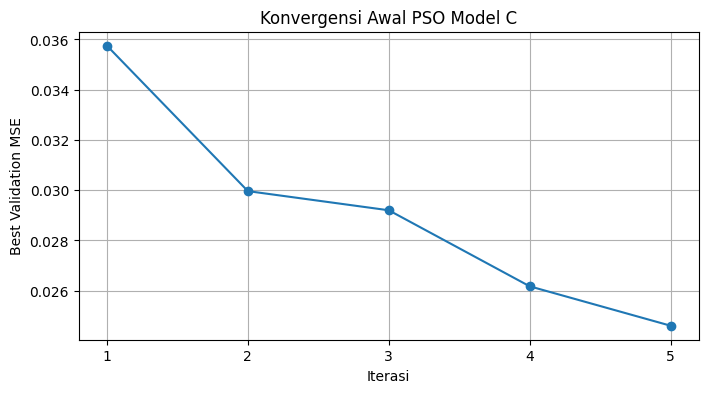


Contoh log evaluasi partikel:


,Iterasi,Partikel,Hidden,Sequence,Learning_Rate,Fitness
0,1,1,64,144,0.001000,0.038608
1,1,2,64,48,0.002761,0.035750
2,1,3,96,144,0.000155,0.104585
3,1,4,64,96,0.002339,0.050858
4,1,5,64,144,0.000452,0.089169
5,1,6,32,96,0.000124,0.342921
6,2,1,64,96,0.001381,0.048056
7,2,2,64,48,0.002761,0.035750
8,2,3,64,96,0.003000,0.029962
9,2,4,64,48,0.002501,0.044529



Implementasi awal PSO berhasil.


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Parameter PSO
W = 0.7
C1 = 1.4
C2 = 1.4

rng = np.random.default_rng(42)

# Inisialisasi posisi enam partikel
posisi = rng.uniform(
    BATAS_BAWAH,
    BATAS_ATAS,
    size=(N_PARTICLES, 3)
)

# Memasukkan konfigurasi baseline sebagai kandidat
posisi[0] = np.array([
    1, 2, np.log10(0.001)
])

kecepatan = np.zeros_like(posisi)

personal_best = posisi.copy()
personal_fitness = np.full(
    N_PARTICLES, np.inf
)

global_best = None
global_fitness = np.inf

riwayat_konvergensi = []
log_partikel = []

mulai = time.perf_counter()

print("=== OPTIMASI AWAL PSO MODEL C ===")

for iterasi in range(N_ITERATIONS):

    for i in range(N_PARTICLES):

        # Menghitung fitness partikel
        nilai_fitness = fitness_pso(
            posisi[i], X_all
        )

        # Memperbarui personal best
        if nilai_fitness < personal_fitness[i]:
            personal_fitness[i] = nilai_fitness
            personal_best[i] = posisi[i].copy()

        # Memperbarui global best
        if nilai_fitness < global_fitness:
            global_fitness = nilai_fitness
            global_best = posisi[i].copy()

        # Menyimpan hasil setiap evaluasi
        cfg = decode_partikel(posisi[i])

        log_partikel.append({
            "Iterasi": iterasi + 1,
            "Partikel": i + 1,
            "Hidden": cfg["hidden_units"],
            "Sequence": cfg["sequence_length"],
            "Learning_Rate": cfg["learning_rate"],
            "Fitness": nilai_fitness
        })

    # Mencatat konvergensi
    riwayat_konvergensi.append(global_fitness)

    print(
        f"Iterasi {iterasi + 1}: "
        f"Best Fitness = {global_fitness:.6f}"
    )

    # Memperbarui posisi untuk iterasi berikutnya
    if iterasi < N_ITERATIONS - 1:

        r1 = rng.random(posisi.shape)
        r2 = rng.random(posisi.shape)

        kecepatan = (
            W * kecepatan
            + C1 * r1 * (personal_best - posisi)
            + C2 * r2 * (global_best - posisi)
        )

        posisi = np.clip(
            posisi + kecepatan,
            BATAS_BAWAH,
            BATAS_ATAS
        )

durasi_pso = time.perf_counter() - mulai

# Menampilkan konfigurasi terbaik
hasil_terbaik_C_awal = decode_partikel(
    global_best
)

print("\n=== HASIL TERBAIK PSO AWAL ===")

for nama, nilai in hasil_terbaik_C_awal.items():
    print(nama, ":", nilai)

print("Best Validation MSE:",
      round(global_fitness, 6))
print("Waktu:", round(durasi_pso, 2), "detik")

# Grafik konvergensi
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, N_ITERATIONS + 1),
    riwayat_konvergensi,
    marker="o"
)

plt.title("Konvergensi Awal PSO Model C")
plt.xlabel("Iterasi")
plt.ylabel("Best Validation MSE")
plt.xticks(range(1, N_ITERATIONS + 1))
plt.grid(True)
plt.show()

# Menyimpan log ke DataFrame
df_log_pso_C_awal = pd.DataFrame(
    log_partikel
)

print("\nContoh log evaluasi partikel:")
display(df_log_pso_C_awal.head(10))

assert np.isfinite(global_fitness)
assert len(riwayat_konvergensi) == N_ITERATIONS

print("\nImplementasi awal PSO berhasil.")

**Interpretasi Hasil Tahap 9**

Implementasi awal *Particle Swarm Optimization* (PSO) pada Model C berhasil dilakukan menggunakan enam partikel dan lima iterasi. Berdasarkan grafik konvergensi, nilai *Validation MSE* terbaik mengalami penurunan dari sekitar 0,035750 pada iterasi pertama menjadi 0,024604 pada iterasi kelima. Konfigurasi terbaik sementara diperoleh pada 96 *hidden units*, *sequence length* 144, dan *learning rate* sekitar 0,002965. Penurunan tersebut menunjukkan bahwa mekanisme pembaruan posisi partikel mampu menemukan konfigurasi dengan kesalahan validasi yang lebih rendah selama proses pencarian. Meskipun demikian, hasil ini masih berasal dari pelatihan singkat menggunakan sampel terbatas, sehingga konfigurasi yang ditemukan perlu divalidasi kembali sebelum digunakan dalam pengujian akhir.

## Tahap 10. Implementasi PSO pada Model D (GA + PSO + RNN)

**Tujuan**

Tahap ini bertujuan untuk mengimplementasikan *Particle Swarm Optimization* (PSO) pada Model D yang menggunakan 10 fitur terpilih dari proses *Genetic Algorithm* (GA) Minggu 13. Optimasi dilakukan untuk mencari kombinasi hiperparameter RNN berdasarkan nilai kesalahan validasi.

**Proses yang Dilakukan**

1. Menggunakan 10 fitur hasil seleksi GA sebagai masukan RNN.
2. Menginisialisasi enam partikel dengan lima iterasi PSO.
3. Mengoptimalkan jumlah *hidden units*, *sequence length*, dan *learning rate* menggunakan ruang pencarian yang sama dengan Model C.
4. Mengevaluasi setiap partikel berdasarkan *Validation MSE*.
5. Mencatat konfigurasi terbaik sementara dan memvisualisasikan kurva konvergensi PSO.

**Hasil yang Diharapkan**

Diperoleh konfigurasi hiperparameter terbaik sementara untuk Model D beserta nilai *fitness*, waktu komputasi, dan grafik konvergensi. Hasil tersebut akan digunakan sebagai kandidat untuk pelatihan ulang dan evaluasi akhir dengan dataset yang lebih lengkap.

=== OPTIMASI AWAL PSO MODEL D ===
Iterasi 1: Best Fitness = 0.065039
Iterasi 2: Best Fitness = 0.048004
Iterasi 3: Best Fitness = 0.048004
Iterasi 4: Best Fitness = 0.048004
Iterasi 5: Best Fitness = 0.048004

=== HASIL TERBAIK PSO MODEL D ===
hidden_units : 64
sequence_length : 144
learning_rate : 0.0013611570700396108
Best Validation MSE: 0.048004
Waktu komputasi: 8.26 detik


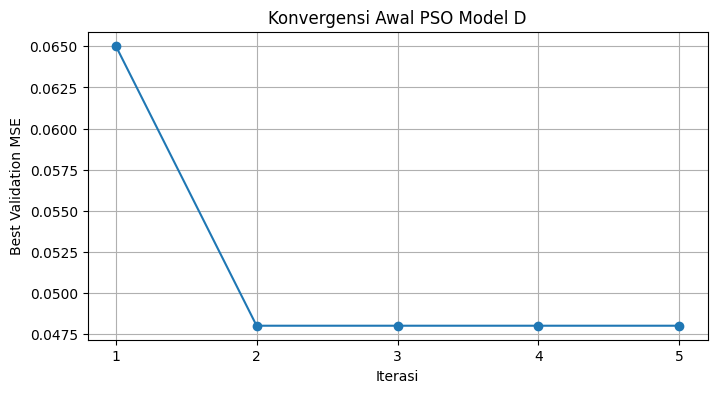


Contoh log evaluasi partikel:


,Iterasi,Partikel,Hidden,Sequence,Learning_Rate,Fitness
0,1,1,64,144,0.001000,0.065039
1,1,2,64,48,0.002761,0.077884
2,1,3,96,144,0.000155,0.134348
3,1,4,64,96,0.002339,0.085897
4,1,5,64,144,0.000452,0.153457
5,1,6,32,96,0.000124,0.461795
6,2,1,64,144,0.001000,0.065039
7,2,2,64,96,0.000845,0.082202
8,2,3,64,144,0.001361,0.048004
9,2,4,64,96,0.001660,0.055293



Implementasi awal PSO Model D berhasil.


In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# ==========================================
# TAHAP 10: PSO MODEL D (GA + PSO + RNN)
# ==========================================

# Parameter PSO sama dengan Model C
W = 0.7
C1 = 1.4
C2 = 1.4

# Seed sama agar inisialisasi dapat dibandingkan
rng_D = np.random.default_rng(42)

# 1. Inisialisasi partikel Model D
posisi_D = rng_D.uniform(
    BATAS_BAWAH,
    BATAS_ATAS,
    size=(N_PARTICLES, 3)
)

# Memasukkan konfigurasi awal sebagai kandidat
posisi_D[0] = np.array([
    1, 2, np.log10(0.001)
])

kecepatan_D = np.zeros_like(posisi_D)

personal_best_D = posisi_D.copy()
personal_fitness_D = np.full(
    N_PARTICLES, np.inf
)

global_best_D = None
global_fitness_D = np.inf

riwayat_konvergensi_D = []
log_partikel_D = []

mulai_D = time.perf_counter()

print("=== OPTIMASI AWAL PSO MODEL D ===")

# 2. Proses optimasi PSO
for iterasi in range(N_ITERATIONS):

    for i in range(N_PARTICLES):

        # Menggunakan 10 fitur GA, bukan 18 fitur
        nilai_fitness = fitness_pso(
            posisi_D[i],
            X_ga_all
        )

        # Memperbarui personal best
        if nilai_fitness < personal_fitness_D[i]:
            personal_fitness_D[i] = nilai_fitness
            personal_best_D[i] = posisi_D[i].copy()

        # Memperbarui global best
        if nilai_fitness < global_fitness_D:
            global_fitness_D = nilai_fitness
            global_best_D = posisi_D[i].copy()

        # Mencatat hasil evaluasi
        cfg = decode_partikel(posisi_D[i])

        log_partikel_D.append({
            "Iterasi": iterasi + 1,
            "Partikel": i + 1,
            "Hidden": cfg["hidden_units"],
            "Sequence": cfg["sequence_length"],
            "Learning_Rate": cfg["learning_rate"],
            "Fitness": nilai_fitness
        })

    riwayat_konvergensi_D.append(global_fitness_D)

    print(
        f"Iterasi {iterasi + 1}: "
        f"Best Fitness = {global_fitness_D:.6f}"
    )

    # Memperbarui posisi dan kecepatan partikel
    if iterasi < N_ITERATIONS - 1:

        r1 = rng_D.random(posisi_D.shape)
        r2 = rng_D.random(posisi_D.shape)

        kecepatan_D = (
            W * kecepatan_D
            + C1 * r1 * (personal_best_D - posisi_D)
            + C2 * r2 * (global_best_D - posisi_D)
        )

        posisi_D = np.clip(
            posisi_D + kecepatan_D,
            BATAS_BAWAH,
            BATAS_ATAS
        )

# 3. Mengambil hasil terbaik sementara
durasi_pso_D = time.perf_counter() - mulai_D

hasil_terbaik_D_awal = decode_partikel(
    global_best_D
)

print("\n=== HASIL TERBAIK PSO MODEL D ===")

for nama, nilai in hasil_terbaik_D_awal.items():
    print(nama, ":", nilai)

print(
    "Best Validation MSE:",
    round(global_fitness_D, 6)
)

print(
    "Waktu komputasi:",
    round(durasi_pso_D, 2),
    "detik"
)

# 4. Grafik konvergensi
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, N_ITERATIONS + 1),
    riwayat_konvergensi_D,
    marker="o"
)

plt.title("Konvergensi Awal PSO Model D")
plt.xlabel("Iterasi")
plt.ylabel("Best Validation MSE")
plt.xticks(range(1, N_ITERATIONS + 1))
plt.grid(True)
plt.show()

# 5. Menyimpan log evaluasi
df_log_pso_D_awal = pd.DataFrame(
    log_partikel_D
)

print("\nContoh log evaluasi partikel:")
display(df_log_pso_D_awal.head(10))

# Pemeriksaan hasil
assert np.isfinite(global_fitness_D)
assert len(riwayat_konvergensi_D) == N_ITERATIONS
assert len(df_log_pso_D_awal) == N_PARTICLES * N_ITERATIONS

print("\nImplementasi awal PSO Model D berhasil.")

**Interpretasi Hasil Tahap 10**

Implementasi awal PSO pada Model D berhasil dilakukan menggunakan 10 fitur hasil seleksi GA, enam partikel, dan lima iterasi. Berdasarkan grafik konvergensi, nilai *Validation MSE* terbaik mengalami penurunan dari 0,065039 pada iterasi pertama menjadi 0,048004 pada iterasi kedua, kemudian tetap konstan hingga iterasi kelima. Konfigurasi terbaik sementara diperoleh pada 64 *hidden units*, *sequence length* 144, dan *learning rate* sekitar 0,001361, dengan waktu komputasi 8,26 detik. Apabila dibandingkan dengan Model C yang memperoleh *Validation MSE* sebesar 0,024604, Model D masih menunjukkan kesalahan validasi yang lebih tinggi pada pengujian awal. Hasil ini belum dapat digunakan untuk menetapkan model terbaik karena proses optimasi masih dilakukan menggunakan sampel terbatas dan satu *epoch*. Oleh karena itu, kedua konfigurasi perlu dievaluasi kembali melalui pelatihan yang lebih representatif dan pengujian akhir pada periode data yang sama.

## Tahap 11. Perbandingan Hasil Optimasi Awal Model C dan Model D

**Tujuan**

Tahap ini bertujuan untuk membandingkan hasil pencarian hiperparameter PSO pada Model C dan Model D berdasarkan konfigurasi terbaik sementara, nilai *Validation MSE*, serta waktu komputasi.

**Proses yang Dilakukan**

Hasil optimasi kedua model disusun ke dalam tabel menggunakan parameter *hidden units*, *sequence length*, *learning rate*, nilai *fitness*, dan durasi pencarian. Perbandingan ini digunakan sebagai evaluasi pendahuluan sebelum dilakukan pelatihan ulang dan pengujian akhir.

**Hasil yang Diharapkan**

Diperoleh tabel perbandingan awal yang menunjukkan perbedaan konfigurasi dan nilai kesalahan validasi kedua model tanpa menyimpulkan performa akhir.

In [11]:

import pandas as pd
import numpy as np

# Membandingkan hasil PSO awal Model C dan Model D
df_perbandingan_awal = pd.DataFrame([
    {
        "Model": "C (PSO + RNN)",
        "Jumlah Fitur": 18,
        "Hidden Units": hasil_terbaik_C_awal["hidden_units"],
        "Sequence Length": hasil_terbaik_C_awal["sequence_length"],
        "Learning Rate": hasil_terbaik_C_awal["learning_rate"],
        "Validation MSE": global_fitness,
        "Waktu (detik)": durasi_pso
    },
    {
        "Model": "D (GA + PSO + RNN)",
        "Jumlah Fitur": 10,
        "Hidden Units": hasil_terbaik_D_awal["hidden_units"],
        "Sequence Length": hasil_terbaik_D_awal["sequence_length"],
        "Learning Rate": hasil_terbaik_D_awal["learning_rate"],
        "Validation MSE": global_fitness_D,
        "Waktu (detik)": durasi_pso_D
    }
])

print("=== PERBANDINGAN AWAL MODEL C DAN D ===")

display(
    df_perbandingan_awal.round(6)
)

model_terbaik_awal = df_perbandingan_awal.loc[
    df_perbandingan_awal["Validation MSE"].idxmin(),
    "Model"
]

print("\nFitness terendah sementara:", model_terbaik_awal)
print("Status: Evaluasi awal, belum pengujian final.")

assert len(df_perbandingan_awal) == 2
assert np.isfinite(
    df_perbandingan_awal["Validation MSE"]
).all()

print("\nPerbandingan awal berhasil.")

=== PERBANDINGAN AWAL MODEL C DAN D ===


,Model,Jumlah Fitur,Hidden Units,Sequence Length,Learning Rate,Validation MSE,Waktu (detik)
0,C (PSO + RNN),18,96,144,0.002065,0.024604,8.895415
1,D (GA + PSO + RNN),10,64,144,0.001361,0.048004,8.258811



Fitness terendah sementara: C (PSO + RNN)
Status: Evaluasi awal, belum pengujian final.

Perbandingan awal berhasil.


**Interpretasi Hasil Tahap 11**

Perbandingan awal menunjukkan bahwa Model C (PSO + RNN) memperoleh *Validation MSE* sebesar 0,024604, lebih rendah dibandingkan Model D (GA + PSO + RNN) sebesar 0,048004. Konfigurasi terbaik sementara Model C menggunakan 96 *hidden units*, *sequence length* 144, dan *learning rate* sekitar 0,002065, sedangkan Model D menggunakan 64 *hidden units*, *sequence length* 144, dan *learning rate* sekitar 0,001361. Hasil tersebut menunjukkan bahwa kombinasi GA dan PSO belum memberikan kesalahan validasi yang lebih rendah dibandingkan PSO saja pada pengujian awal. Akan tetapi, perbandingan ini masih bersifat pendahuluan karena dilakukan menggunakan sampel terbatas dan satu *epoch*, sehingga diperlukan pelatihan yang lebih representatif sebelum mengevaluasi performa akhir kedua model.

## Tahap 12. Pelatihan Ulang Kandidat PSO Model C

**Tujuan**

Tahap ini bertujuan untuk menguji konfigurasi hiperparameter hasil pencarian awal PSO pada Model C menggunakan seluruh data pelatihan dan validasi.

**Proses yang Dilakukan**

1. Membentuk model RNN berdasarkan konfigurasi terbaik sementara hasil PSO.
2. Menggunakan seluruh sampel pelatihan untuk memperbarui bobot jaringan.
3. Menghitung *Training MSE* dan *Validation MSE*.
4. Mencatat waktu komputasi satu *epoch* sebagai pertimbangan kelanjutan pelatihan.

**Hasil yang Diharapkan**

Diperoleh hasil pelatihan dan validasi satu *epoch* pada dataset yang lebih lengkap, sekaligus informasi waktu komputasi. Tahap ini belum merupakan evaluasi akhir pada data *testing*.

In [12]:

import time
import copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Reproduksibilitas inisialisasi
torch.manual_seed(42)

# Konfigurasi terbaik sementara hasil PSO Model C
cfg_C = hasil_terbaik_C_awal

# Membentuk dataset untuk pelatihan penuh
train_C_final = DatasetSequenceRNN(
    X_all, y_all,
    max(SEQ_OPTIONS),
    batas_train,
    cfg_C["sequence_length"]
)

val_C_final = DatasetSequenceRNN(
    X_all, y_all,
    batas_train,
    batas_val,
    cfg_C["sequence_length"]
)

# DataLoader
loader_train_C_final = DataLoader(
    train_C_final,
    batch_size=256,
    shuffle=True,
    num_workers=0
)

loader_val_C_final = DataLoader(
    val_C_final,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

# Membuat model berdasarkan hasil PSO
model_C_final = RNNMultiZona(
    input_size=X_all.shape[1],
    hidden_size=cfg_C["hidden_units"]
).to(device)

optimizer_C_final = torch.optim.Adam(
    model_C_final.parameters(),
    lr=cfg_C["learning_rate"]
)

criterion_C_final = nn.MSELoss()
riwayat_training_C = []

mulai = time.perf_counter()

# Pelatihan satu epoch
model_C_final.train()
total_train = 0.0
jumlah_train = 0

for xb, yb in loader_train_C_final:
    xb = xb.to(device)
    yb = yb.to(device)

    optimizer_C_final.zero_grad()
    pred = model_C_final(xb)
    loss = criterion_C_final(pred, yb)

    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        model_C_final.parameters(), 1.0
    )
    optimizer_C_final.step()

    total_train += loss.item() * len(xb)
    jumlah_train += len(xb)

train_mse_C = total_train / jumlah_train

# Evaluasi pada seluruh data validation
model_C_final.eval()
total_val = 0.0
jumlah_val = 0

with torch.no_grad():
    for xb, yb in loader_val_C_final:
        xb = xb.to(device)
        yb = yb.to(device)

        loss = criterion_C_final(
            model_C_final(xb), yb
        )

        total_val += loss.item() * len(xb)
        jumlah_val += len(xb)

val_mse_C = total_val / jumlah_val
waktu_epoch_C = time.perf_counter() - mulai

# Menyimpan bobot untuk kelanjutan pelatihan
best_state_C = copy.deepcopy(
    model_C_final.state_dict()
)
best_val_C = val_mse_C

riwayat_training_C.append({
    "Epoch": 1,
    "Train MSE": train_mse_C,
    "Val MSE": val_mse_C
})

print("=== HASIL TAHAP 12 MODEL C ===")
print("Jumlah training:", jumlah_train)
print("Jumlah validation:", jumlah_val)
print("Hidden units:", cfg_C["hidden_units"])
print("Sequence:", cfg_C["sequence_length"])
print("Learning rate:", round(
    cfg_C["learning_rate"], 6
))

print("\nTraining MSE:", round(train_mse_C, 6))
print("Validation MSE:", round(val_mse_C, 6))
print("Waktu 1 epoch:",
      round(waktu_epoch_C, 2), "detik")

print("\nEpoch pertama berhasil.")

=== HASIL TAHAP 12 MODEL C ===
Jumlah training: 36446
Jumlah validation: 7840
Hidden units: 96
Sequence: 144
Learning rate: 0.002065

Training MSE: 0.005849
Validation MSE: 0.001943
Waktu 1 epoch: 33.57 detik

Epoch pertama berhasil.


**Interpretasi Hasil Tahap 12**

Pelatihan awal Model C menggunakan konfigurasi hasil PSO berhasil dilakukan terhadap 36.446 sampel pelatihan dan 7.840 sampel validasi. Konfigurasi model terdiri atas 96 *hidden units*, *sequence length* 144, dan *learning rate* sebesar 0,002065. Setelah satu *epoch*, diperoleh *Training MSE* sebesar 0,005849 dan *Validation MSE* sebesar 0,001943 dengan waktu komputasi 33,57 detik. Hasil tersebut menunjukkan bahwa konfigurasi RNN dapat dilatih menggunakan keseluruhan data yang disiapkan. Meskipun demikian, pelatihan perlu dilanjutkan untuk memeriksa perkembangan kesalahan dan menentukan bobot model terbaik berdasarkan hasil validasi.

## Tahap 13. Kelanjutan Pelatihan Model C

**Tujuan**

Tahap ini bertujuan untuk melanjutkan pelatihan Model C menggunakan konfigurasi hasil PSO dan memantau perkembangan kesalahan pada data pelatihan serta validasi.

**Proses yang Dilakukan**

Pelatihan dilanjutkan dari bobot model pada *epoch* pertama tanpa melakukan inisialisasi ulang. Setiap *epoch* menghasilkan nilai *Training MSE* dan *Validation MSE*. Bobot model dengan kesalahan validasi terendah disimpan sebagai kandidat terbaik untuk pengujian akhir.

**Hasil yang Diharapkan**

Diperoleh perkembangan nilai MSE pada *epoch* berikutnya serta bobot model terbaik berdasarkan data validasi, tanpa menggunakan data pengujian selama proses pelatihan.

In [13]:

import time
import copy
import pandas as pd
import torch

# Melanjutkan model dari Tahap 12
# Tidak membuat ulang model atau optimizer

for epoch in range(2, 4):

    mulai_epoch = time.perf_counter()

    # Training
    model_C_final.train()
    total_train = 0.0
    jumlah_train = 0

    for xb, yb in loader_train_C_final:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_C_final.zero_grad()

        prediksi = model_C_final(xb)
        loss = criterion_C_final(prediksi, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_C_final.parameters(), 1.0
        )

        optimizer_C_final.step()

        total_train += loss.item() * len(xb)
        jumlah_train += len(xb)

    train_mse = total_train / jumlah_train

    # Validation
    model_C_final.eval()
    total_val = 0.0
    jumlah_val = 0

    with torch.no_grad():
        for xb, yb in loader_val_C_final:
            xb = xb.to(device)
            yb = yb.to(device)

            prediksi = model_C_final(xb)
            loss = criterion_C_final(prediksi, yb)

            total_val += loss.item() * len(xb)
            jumlah_val += len(xb)

    val_mse = total_val / jumlah_val

    # Menyimpan bobot terbaik
    if val_mse < best_val_C:
        best_val_C = val_mse
        best_state_C = copy.deepcopy(
            model_C_final.state_dict()
        )

    waktu = time.perf_counter() - mulai_epoch

    riwayat_training_C.append({
        "Epoch": epoch,
        "Train MSE": train_mse,
        "Val MSE": val_mse
    })

    print(
        f"Epoch {epoch} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Waktu: {waktu:.2f} detik"
    )

print("\n=== RINGKASAN PELATIHAN MODEL C ===")

df_riwayat_C = pd.DataFrame(riwayat_training_C)
display(df_riwayat_C.round(6))

print("\nBest Validation MSE:",
      round(best_val_C, 6))

print("Pelatihan sampai epoch 3 berhasil.")

Epoch 2 | Train MSE: 0.000737 | Val MSE: 0.000591 | Waktu: 20.08 detik
Epoch 3 | Train MSE: 0.000508 | Val MSE: 0.000520 | Waktu: 19.50 detik

=== RINGKASAN PELATIHAN MODEL C ===


,Epoch,Train MSE,Val MSE
0,1,0.005849,0.001943
1,2,0.000737,0.000591
2,3,0.000508,0.000520



Best Validation MSE: 0.00052
Pelatihan sampai epoch 3 berhasil.


**Interpretasi Hasil Tahap 13**

Pelatihan lanjutan Model C menunjukkan penurunan nilai *Training MSE* dari 0,005849 pada *epoch* pertama menjadi 0,000508 pada *epoch* ketiga. Nilai *Validation MSE* juga mengalami penurunan dari 0,001943 menjadi 0,000520. Perkembangan ini menunjukkan bahwa model mampu memperbaiki hasil prediksinya pada data pelatihan dan validasi selama proses pembelajaran. Nilai kesalahan validasi terendah sementara diperoleh pada *epoch* ketiga, sehingga bobot model pada tahap tersebut disimpan sebagai kandidat terbaik. Meskipun demikian, proses pelatihan masih perlu dievaluasi lebih lanjut sebelum dilakukan pengujian akhir menggunakan data *testing*.

## Tahap 14. Penyelesaian Pelatihan Model C

**Tujuan**

Tahap ini bertujuan untuk menyelesaikan pelatihan Model C hingga lima *epoch* serta menentukan bobot model terbaik berdasarkan nilai kesalahan validasi.

**Proses yang Dilakukan**

Pelatihan dilanjutkan dari *epoch* ketiga menuju *epoch* keempat dan kelima. Pada setiap *epoch*, dihitung nilai *Training MSE* dan *Validation MSE*. Bobot model dengan kesalahan validasi terendah dipertahankan sebagai dasar evaluasi akhir.

**Hasil yang Diharapkan**

Diperoleh riwayat pelatihan lengkap selama lima *epoch* dan nilai *Validation MSE* terbaik yang digunakan untuk memilih bobot Model C.

In [14]:

# Melanjutkan pelatihan Model C dari epoch 3
# Jangan menjalankan ulang Tahap 12 atau 13

import time
import copy
import pandas as pd
import torch

for epoch in range(4, 6):
    mulai_epoch = time.perf_counter()

    # Training
    model_C_final.train()
    total_train = 0.0
    jumlah_train = 0

    for xb, yb in loader_train_C_final:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_C_final.zero_grad()
        prediksi = model_C_final(xb)
        loss = criterion_C_final(prediksi, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model_C_final.parameters(), 1.0
        )
        optimizer_C_final.step()

        total_train += loss.item() * len(xb)
        jumlah_train += len(xb)

    train_mse = total_train / jumlah_train

    # Validation
    model_C_final.eval()
    total_val = 0.0
    jumlah_val = 0

    with torch.no_grad():
        for xb, yb in loader_val_C_final:
            xb = xb.to(device)
            yb = yb.to(device)

            loss = criterion_C_final(
                model_C_final(xb), yb
            )

            total_val += loss.item() * len(xb)
            jumlah_val += len(xb)

    val_mse = total_val / jumlah_val

    if val_mse < best_val_C:
        best_val_C = val_mse
        best_state_C = copy.deepcopy(
            model_C_final.state_dict()
        )

    riwayat_training_C.append({
        "Epoch": epoch,
        "Train MSE": train_mse,
        "Val MSE": val_mse
    })

    waktu = time.perf_counter() - mulai_epoch

    print(
        f"Epoch {epoch} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Waktu: {waktu:.2f} detik"
    )

print("\n=== HASIL PELATIHAN MODEL C ===")

df_riwayat_C = pd.DataFrame(riwayat_training_C)
display(df_riwayat_C.round(6))

print("\nBest Validation MSE:",
      round(best_val_C, 6))

print("Pelatihan 5 epoch selesai.")

Epoch 4 | Train MSE: 0.000433 | Val MSE: 0.000463 | Waktu: 21.06 detik
Epoch 5 | Train MSE: 0.000394 | Val MSE: 0.000563 | Waktu: 19.31 detik

=== HASIL PELATIHAN MODEL C ===


,Epoch,Train MSE,Val MSE
0,1,0.005849,0.001943
1,2,0.000737,0.000591
2,3,0.000508,0.000520
3,4,0.000433,0.000463
4,5,0.000394,0.000563



Best Validation MSE: 0.000463
Pelatihan 5 epoch selesai.


**Interpretasi Hasil Tahap 14**

Pelatihan Model C selama lima *epoch* menunjukkan penurunan *Training MSE* dari 0,005849 menjadi 0,000394. Sementara itu, *Validation MSE* mencapai nilai terendah sebesar 0,000463 pada *epoch* keempat, kemudian meningkat menjadi 0,000563 pada *epoch* kelima. Kondisi tersebut menunjukkan bahwa penurunan kesalahan pelatihan tidak selalu diikuti perbaikan pada data validasi. Oleh karena itu, bobot model pada *epoch* keempat dipilih sebagai konfigurasi terbaik berdasarkan kriteria validasi. Bobot tersebut selanjutnya digunakan untuk mengevaluasi performa Model C terhadap data pengujian yang belum digunakan selama pelatihan maupun pemilihan model.

## Tahap 15. Evaluasi Model C pada Data Testing

**Tujuan**

Tahap ini bertujuan untuk mengukur performa Model C (PSO + RNN) dalam memprediksi konsumsi listrik pada tiga zona menggunakan data pengujian yang tidak dilibatkan dalam pelatihan dan pemilihan hiperparameter.

**Proses yang Dilakukan**

1. Memuat bobot model terbaik berdasarkan hasil validasi pada *epoch* keempat.
2. Melakukan prediksi menggunakan seluruh data *testing*.
3. Mengembalikan nilai prediksi dan target ke skala aslinya melalui *inverse transform*.
4. Menghitung MAE, RMSE, dan R² untuk masing-masing zona.
5. Menghitung rata-rata metrik ketiga zona sebagai ringkasan evaluasi.

**Hasil yang Diharapkan**

Diperoleh tabel evaluasi akhir Model C pada tiga zona konsumsi listrik. Hasil tersebut digunakan sebagai pembanding terhadap Model D setelah kedua model selesai diuji menggunakan periode data yang sama.

In [15]:

import copy
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Menggunakan bobot terbaik dari validation
model_C_final.load_state_dict(
    copy.deepcopy(best_state_C)
)

model_C_final.eval()

# 2. Membentuk dataset testing
test_C_final = DatasetSequenceRNN(
    X_all,
    y_all,
    batas_val,
    batas_test,
    cfg_C["sequence_length"]
)

loader_test_C_final = DataLoader(
    test_C_final,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

# 3. Mengumpulkan prediksi dan target
prediksi_C = []
aktual_C = []

with torch.no_grad():
    for xb, yb in loader_test_C_final:
        xb = xb.to(device)

        hasil = model_C_final(xb)

        prediksi_C.append(
            hasil.cpu().numpy()
        )

        aktual_C.append(
            yb.numpy()
        )

prediksi_C = np.concatenate(prediksi_C)
aktual_C = np.concatenate(aktual_C)

# 4. Mengembalikan ke skala asli
prediksi_C_asli = scaler_y.inverse_transform(
    prediksi_C
)

aktual_C_asli = scaler_y.inverse_transform(
    aktual_C
)

# 5. Menghitung metrik setiap zona
hasil_evaluasi_C = []

for i in range(3):
    y_true = aktual_C_asli[:, i]
    y_pred = prediksi_C_asli[:, i]

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    hasil_evaluasi_C.append({
        "Zona": f"Zona {i+1}",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_evaluasi_C = pd.DataFrame(
    hasil_evaluasi_C
)

# 6. Menambahkan rata-rata antar zona
rata_rata_C = {
    "Zona": "Rata-rata",
    "MAE": df_evaluasi_C["MAE"].mean(),
    "RMSE": df_evaluasi_C["RMSE"].mean(),
    "R2": df_evaluasi_C["R2"].mean()
}

df_evaluasi_C = pd.concat(
    [
        df_evaluasi_C,
        pd.DataFrame([rata_rata_C])
    ],
    ignore_index=True
)

# 7. Pemeriksaan hasil
assert len(prediksi_C_asli) == 7842
assert prediksi_C_asli.shape == (7842, 3)
assert np.isfinite(prediksi_C_asli).all()

print("=== EVALUASI AKHIR MODEL C ===")
print("Model: PSO + RNN")
print("Bobot terbaik: Epoch 4")
print("Jumlah data testing:", len(prediksi_C_asli))

print("\nHasil evaluasi:")
display(df_evaluasi_C.round(4))

print("\nEvaluasi Model C berhasil.")

=== EVALUASI AKHIR MODEL C ===
Model: PSO + RNN
Bobot terbaik: Epoch 4
Jumlah data testing: 7842

Hasil evaluasi:


,Zona,MAE,RMSE,R2
0,Zona 1,943.8477,1078.0610,0.9684
1,Zona 2,534.0978,736.5604,0.9827
2,Zona 3,577.1257,824.6311,0.9398
3,Rata-rata,685.0237,879.7508,0.9636



Evaluasi Model C berhasil.


**Interpretasi Hasil Tahap 15**

Evaluasi Model C (PSO + RNN) dilakukan terhadap 7.842 sampel pengujian menggunakan bobot terbaik dari *epoch* keempat. Hasil pengujian menunjukkan nilai rata-rata MAE sebesar 685,0237, RMSE sebesar 879,7508, dan R² sebesar 0,9636. Zona 2 memperoleh R² tertinggi sebesar 0,9827, sedangkan Zona 3 menghasilkan R² terendah sebesar 0,9398. Perbedaan tersebut menunjukkan bahwa kemampuan model dalam menjelaskan variasi konsumsi listrik tidak sepenuhnya sama pada setiap zona. Secara keseluruhan, Model C memperlihatkan kemampuan prediksi yang baik pada periode pengujian, tetapi keunggulannya terhadap konfigurasi lain masih perlu ditentukan melalui perbandingan menggunakan protokol evaluasi yang konsisten.

## Tahap 16. Pelatihan Model D (GA + PSO + RNN)

**Tujuan**

Tahap ini bertujuan untuk melatih Model D menggunakan fitur hasil seleksi *Genetic Algorithm* (GA) dan konfigurasi hiperparameter yang diperoleh dari pencarian *Particle Swarm Optimization* (PSO).

**Proses yang Dilakukan**

Model D menggunakan 10 fitur terpilih GA dengan 64 *hidden units*, *sequence length* 144, dan *learning rate* sekitar 0,001361. Proses pelatihan dilakukan selama lima *epoch* menggunakan seluruh data pelatihan. Setiap *epoch* dievaluasi berdasarkan *Training MSE* dan *Validation MSE*, kemudian bobot dengan nilai kesalahan validasi terendah disimpan sebagai kandidat terbaik.

**Hasil yang Diharapkan**

Diperoleh riwayat pelatihan selama lima *epoch*, nilai kesalahan validasi terbaik, serta bobot Model D yang siap digunakan untuk evaluasi akhir pada data *testing*.

In [16]:

import time
import copy
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# ==========================================
# TAHAP 16: PELATIHAN PENUH MODEL D
# ==========================================

torch.manual_seed(42)

# Konfigurasi terbaik sementara hasil PSO Model D
cfg_D = hasil_terbaik_D_awal.copy()

# Dataset Model D dengan 10 fitur hasil GA
train_D_final = DatasetSequenceRNN(
    X_ga_all,
    y_all,
    max(SEQ_OPTIONS),
    batas_train,
    cfg_D["sequence_length"]
)

val_D_final = DatasetSequenceRNN(
    X_ga_all,
    y_all,
    batas_train,
    batas_val,
    cfg_D["sequence_length"]
)

loader_train_D_final = DataLoader(
    train_D_final,
    batch_size=256,
    shuffle=True,
    num_workers=0
)

loader_val_D_final = DataLoader(
    val_D_final,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

# Membuat model menggunakan konfigurasi PSO
model_D_final = RNNMultiZona(
    input_size=X_ga_all.shape[1],
    hidden_size=cfg_D["hidden_units"]
).to(device)

optimizer_D_final = torch.optim.Adam(
    model_D_final.parameters(),
    lr=cfg_D["learning_rate"]
)

criterion_D_final = nn.MSELoss()

riwayat_training_D = []
best_val_D = float("inf")
best_state_D = None
best_epoch_D = None

mulai_total_D = time.perf_counter()

print("=== PELATIHAN MODEL D ===")
print("Fitur:", X_ga_all.shape[1])
print("Hidden units:", cfg_D["hidden_units"])
print("Sequence length:", cfg_D["sequence_length"])
print("Learning rate:", round(cfg_D["learning_rate"], 6))
print("Training samples:", len(train_D_final))
print("Validation samples:", len(val_D_final))

# Pelatihan selama lima epoch
for epoch in range(1, 6):

    mulai_epoch = time.perf_counter()

    # TRAINING
    model_D_final.train()
    total_train = 0.0
    jumlah_train = 0

    for xb, yb in loader_train_D_final:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_D_final.zero_grad()

        prediksi = model_D_final(xb)
        loss = criterion_D_final(prediksi, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model_D_final.parameters(), 1.0
        )

        optimizer_D_final.step()

        total_train += loss.item() * len(xb)
        jumlah_train += len(xb)

    train_mse = total_train / jumlah_train

    # VALIDATION
    model_D_final.eval()
    total_val = 0.0
    jumlah_val = 0

    with torch.no_grad():
        for xb, yb in loader_val_D_final:
            xb = xb.to(device)
            yb = yb.to(device)

            prediksi = model_D_final(xb)
            loss = criterion_D_final(prediksi, yb)

            total_val += loss.item() * len(xb)
            jumlah_val += len(xb)

    val_mse = total_val / jumlah_val

    # Menyimpan bobot terbaik
    if val_mse < best_val_D:
        best_val_D = val_mse
        best_epoch_D = epoch
        best_state_D = copy.deepcopy(
            model_D_final.state_dict()
        )

    waktu_epoch = time.perf_counter() - mulai_epoch

    riwayat_training_D.append({
        "Epoch": epoch,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Waktu (detik)": waktu_epoch
    })

    print(
        f"Epoch {epoch} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Waktu: {waktu_epoch:.2f} detik",
        flush=True
    )

# Ringkasan hasil
durasi_training_D = time.perf_counter() - mulai_total_D

df_riwayat_D = pd.DataFrame(riwayat_training_D)

print("\n=== HASIL PELATIHAN MODEL D ===")
display(df_riwayat_D.round(6))

print("\nEpoch terbaik:", best_epoch_D)
print("Best Validation MSE:", round(best_val_D, 6))
print("Total waktu:", round(durasi_training_D, 2), "detik")

assert len(df_riwayat_D) == 5
assert best_state_D is not None
assert np.isfinite(best_val_D)

print("\nPelatihan Model D berhasil.")

=== PELATIHAN MODEL D ===
Fitur: 10
Hidden units: 64
Sequence length: 144
Learning rate: 0.001361
Training samples: 36446
Validation samples: 7840
Epoch 1 | Train MSE: 0.016099 | Val MSE: 0.007516 | Waktu: 37.47 detik
Epoch 2 | Train MSE: 0.002050 | Val MSE: 0.002878 | Waktu: 9.74 detik
Epoch 3 | Train MSE: 0.001474 | Val MSE: 0.001956 | Waktu: 10.17 detik
Epoch 4 | Train MSE: 0.001275 | Val MSE: 0.001403 | Waktu: 10.54 detik
Epoch 5 | Train MSE: 0.001220 | Val MSE: 0.001426 | Waktu: 10.91 detik

=== HASIL PELATIHAN MODEL D ===


,Epoch,Train MSE,Val MSE,Waktu (detik)
0,1,0.016099,0.007516,37.472390
1,2,0.002050,0.002878,9.740255
2,3,0.001474,0.001956,10.170710
3,4,0.001275,0.001403,10.535063
4,5,0.001220,0.001426,10.906251



Epoch terbaik: 4
Best Validation MSE: 0.001403
Total waktu: 78.83 detik

Pelatihan Model D berhasil.


**Interpretasi Hasil Tahap 16**

Pelatihan Model D (GA + PSO + RNN) berhasil dilakukan selama lima *epoch* menggunakan 36.446 sampel pelatihan dan 7.840 sampel validasi. Model menggunakan 10 fitur hasil seleksi GA dengan konfigurasi 64 *hidden units*, *sequence length* 144, dan *learning rate* sebesar 0,001361. Hasil pelatihan menunjukkan penurunan *Training MSE* dari 0,016099 menjadi 0,001220. Sementara itu, *Validation MSE* mencapai nilai terendah sebesar 0,001403 pada *epoch* keempat, kemudian sedikit meningkat menjadi 0,001426 pada *epoch* kelima. Oleh karena itu, bobot pada *epoch* keempat dipilih untuk evaluasi akhir. Total waktu pelatihan tercatat sebesar 78,83 detik.

## Tahap 17. Evaluasi Model D pada Data Testing

**Tujuan**

Tahap ini bertujuan untuk mengevaluasi kemampuan prediksi Model D (GA + PSO + RNN) terhadap konsumsi listrik tiga zona menggunakan data *testing* yang tidak dilibatkan dalam pelatihan maupun pemilihan hiperparameter.

**Proses yang Dilakukan**

1. Memuat bobot terbaik Model D dari *epoch* keempat.
2. Menghasilkan prediksi pada seluruh sampel pengujian.
3. Mengembalikan nilai prediksi dan aktual ke skala konsumsi listrik asli.
4. Menghitung MAE, RMSE, dan R² pada setiap zona.
5. Menghitung rata-rata metrik ketiga zona sebagai ringkasan performa.

**Hasil yang Diharapkan**

Diperoleh tabel evaluasi akhir Model D yang dapat dibandingkan dengan Model C pada periode pengujian yang sama.

In [17]:

import copy
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Memuat bobot terbaik Model D
model_D_final.load_state_dict(
    copy.deepcopy(best_state_D)
)
model_D_final.eval()

# 2. Membentuk data testing Model D
test_D_final = DatasetSequenceRNN(
    X_ga_all,
    y_all,
    batas_val,
    batas_test,
    cfg_D["sequence_length"]
)

loader_test_D_final = DataLoader(
    test_D_final,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

# 3. Mengumpulkan hasil prediksi
prediksi_D = []
aktual_D = []

with torch.no_grad():
    for xb, yb in loader_test_D_final:
        xb = xb.to(device)

        hasil = model_D_final(xb)

        prediksi_D.append(
            hasil.cpu().numpy()
        )
        aktual_D.append(
            yb.numpy()
        )

prediksi_D = np.concatenate(prediksi_D)
aktual_D = np.concatenate(aktual_D)

# 4. Mengembalikan ke skala asli
prediksi_D_asli = scaler_y.inverse_transform(
    prediksi_D
)

aktual_D_asli = scaler_y.inverse_transform(
    aktual_D
)

# 5. Memastikan periode testing sama dengan Model C
assert prediksi_D_asli.shape == (7842, 3)
assert np.allclose(aktual_C_asli, aktual_D_asli)
assert np.isfinite(prediksi_D_asli).all()

# 6. Menghitung metrik setiap zona
hasil_evaluasi_D = []

for i in range(3):
    y_true = aktual_D_asli[:, i]
    y_pred = prediksi_D_asli[:, i]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )
    r2 = r2_score(y_true, y_pred)

    hasil_evaluasi_D.append({
        "Zona": f"Zona {i+1}",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_evaluasi_D = pd.DataFrame(
    hasil_evaluasi_D
)

# 7. Rata-rata metrik ketiga zona
rata_rata_D = {
    "Zona": "Rata-rata",
    "MAE": df_evaluasi_D["MAE"].mean(),
    "RMSE": df_evaluasi_D["RMSE"].mean(),
    "R2": df_evaluasi_D["R2"].mean()
}

df_evaluasi_D = pd.concat(
    [
        df_evaluasi_D,
        pd.DataFrame([rata_rata_D])
    ],
    ignore_index=True
)

print("=== EVALUASI AKHIR MODEL D ===")
print("Model: GA + PSO + RNN")
print("Bobot terbaik: Epoch", best_epoch_D)
print("Jumlah data testing:", len(prediksi_D_asli))

print("\nHasil evaluasi:")
display(df_evaluasi_D.round(4))

print("\nEvaluasi Model D berhasil.")

=== EVALUASI AKHIR MODEL D ===
Model: GA + PSO + RNN
Bobot terbaik: Epoch 4
Jumlah data testing: 7842

Hasil evaluasi:


,Zona,MAE,RMSE,R2
0,Zona 1,2997.5012,3219.6775,0.7182
1,Zona 2,705.0818,993.7342,0.9685
2,Zona 3,984.0356,1301.6260,0.8501
3,Rata-rata,1562.2062,1838.3459,0.8456



Evaluasi Model D berhasil.


**Interpretasi Hasil Tahap 17**

Evaluasi Model D (GA + PSO + RNN) dilakukan menggunakan 7.842 sampel pengujian dengan bobot terbaik dari *epoch* keempat. Hasil pengujian memperoleh nilai rata-rata MAE sebesar 1.562,2062, RMSE sebesar 1.838,3459, dan R² sebesar 0,8456. Zona 2 menghasilkan R² tertinggi sebesar 0,9685, sedangkan Zona 1 memperoleh R² terendah sebesar 0,7182. Hasil tersebut memperlihatkan bahwa kemampuan prediksi Model D belum merata pada ketiga zona. Dibandingkan Model C yang menggunakan 18 fitur, Model D dengan 10 fitur hasil seleksi GA menunjukkan kesalahan prediksi lebih besar pada pengujian ini. Temuan tersebut perlu dianalisis lebih lanjut, khususnya terkait pemilihan fitur dan keterbatasan optimasi hiperparameter, sebelum menyimpulkan pengaruh kombinasi GA dan PSO terhadap performa model.

## Tahap 18. Perbandingan Performa Model C dan Model D

**Tujuan**

Tahap ini bertujuan untuk membandingkan performa Model C (PSO + RNN) dan Model D (GA + PSO + RNN) berdasarkan hasil pengujian konsumsi listrik pada tiga zona.

**Proses yang Dilakukan**

Perbandingan dilakukan menggunakan metrik MAE, RMSE, dan R² pada periode pengujian yang sama. Nilai kesalahan dan kemampuan model dalam menjelaskan variasi konsumsi dianalisis untuk mengetahui pengaruh penggunaan fitur hasil seleksi GA terhadap model yang dioptimalkan menggunakan PSO.

**Hasil yang Diharapkan**

Diperoleh tabel perbandingan Model C dan Model D untuk setiap zona serta nilai rata-ratanya, sehingga perbedaan performa kedua model dapat dianalisis secara terukur.

In [18]:

import pandas as pd
import numpy as np

# Menggabungkan hasil evaluasi Model C dan D
df_C = df_evaluasi_C.copy()
df_D = df_evaluasi_D.copy()

df_C["Model"] = "C (PSO + RNN)"
df_D["Model"] = "D (GA + PSO + RNN)"

df_perbandingan_CD = pd.concat(
    [df_C, df_D],
    ignore_index=True
)

df_perbandingan_CD = df_perbandingan_CD[
    ["Model", "Zona", "MAE", "RMSE", "R2"]
]

print("=== PERBANDINGAN MODEL C DAN D ===")
display(df_perbandingan_CD.round(4))

# Membandingkan rata-rata kedua model
rata_C = df_C[df_C["Zona"] == "Rata-rata"].iloc[0]
rata_D = df_D[df_D["Zona"] == "Rata-rata"].iloc[0]

ringkasan_CD = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "R2"],
    "Model C": [
        rata_C["MAE"],
        rata_C["RMSE"],
        rata_C["R2"]
    ],
    "Model D": [
        rata_D["MAE"],
        rata_D["RMSE"],
        rata_D["R2"]
    ]
})

ringkasan_CD["Selisih D - C"] = (
    ringkasan_CD["Model D"] -
    ringkasan_CD["Model C"]
)

print("\n=== RINGKASAN RATA-RATA ===")
display(ringkasan_CD.round(4))

# Memastikan target aktual kedua model sama
assert np.allclose(
    aktual_C_asli,
    aktual_D_asli
)

assert np.isfinite(
    df_perbandingan_CD[["MAE", "RMSE", "R2"]]
).all().all()

print("\nPeriode dan target testing konsisten.")
print("Perbandingan Model C dan D berhasil.")

=== PERBANDINGAN MODEL C DAN D ===


,Model,Zona,MAE,RMSE,R2
0,C (PSO + RNN),Zona 1,943.8477,1078.0610,0.9684
1,C (PSO + RNN),Zona 2,534.0978,736.5604,0.9827
2,C (PSO + RNN),Zona 3,577.1257,824.6311,0.9398
3,C (PSO + RNN),Rata-rata,685.0237,879.7508,0.9636
4,D (GA + PSO + RNN),Zona 1,2997.5012,3219.6775,0.7182
5,D (GA + PSO + RNN),Zona 2,705.0818,993.7342,0.9685
6,D (GA + PSO + RNN),Zona 3,984.0356,1301.6260,0.8501
7,D (GA + PSO + RNN),Rata-rata,1562.2062,1838.3459,0.8456



=== RINGKASAN RATA-RATA ===


,Metrik,Model C,Model D,Selisih D - C
0,MAE,685.0237,1562.2062,877.1825
1,RMSE,879.7508,1838.3459,958.5950
2,R2,0.9636,0.8456,-0.1180



Periode dan target testing konsisten.
Perbandingan Model C dan D berhasil.


**Interpretasi Hasil Tahap 18**

Hasil perbandingan menunjukkan bahwa Model C (PSO + RNN) memperoleh performa prediksi lebih baik dibandingkan Model D (GA + PSO + RNN) pada periode pengujian yang sama. Model C menghasilkan rata-rata MAE sebesar 685,0237, RMSE sebesar 879,7508, dan R² sebesar 0,9636. Sementara itu, Model D memperoleh rata-rata MAE sebesar 1.562,2062, RMSE sebesar 1.838,3459, dan R² sebesar 0,8456. Perbedaan tersebut menunjukkan bahwa penggunaan 10 fitur hasil seleksi GA belum memberikan peningkatan performa dibandingkan penggunaan 18 fitur pada Model C. Hasil ini dapat dipengaruhi oleh kombinasi fitur terpilih, konfigurasi hiperparameter, serta proses pencarian PSO yang masih terbatas. Oleh karena itu, hasil eksperimen tidak dapat digunakan untuk menyimpulkan bahwa penerapan GA selalu menurunkan akurasi RNN.

## Tahap 19. Penyelarasan dan Perbandingan Empat Model

### 19A. Pelatihan Ulang Model A (Baseline RNN)

**Tujuan**

Tahap ini bertujuan untuk membangun kembali Model A sebagai pembanding terhadap Model B, C, dan D menggunakan prosedur pengolahan data yang sama.

**Proses yang Dilakukan**

Model A menggunakan 18 kandidat fitur tanpa seleksi GA maupun optimasi PSO. Konfigurasi awal ditetapkan sebanyak 64 *hidden units*, *sequence length* 144, *learning rate* 0,001, dan lima *epoch*. Pelatihan dilakukan pada data *training*, sedangkan pemilihan bobot terbaik menggunakan *Validation MSE*. Periode data pengujian dipertahankan sama dengan Model C dan D.

**Hasil yang Diharapkan**

Diperoleh riwayat pelatihan, nilai *Validation MSE*, dan bobot terbaik Model A yang selanjutnya digunakan untuk evaluasi MAE, RMSE, dan R². Hasil ini merupakan baseline yang diselaraskan untuk eksperimen Minggu 14, bukan penggantian hasil asli Minggu 12.

In [19]:

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import copy
import time
from torch.utils.data import DataLoader

# ==========================================
# TAHAP 19A: BASELINE RNN MODEL A
# ==========================================

torch.manual_seed(42)
np.random.seed(42)

# Konfigurasi awal tanpa optimasi
HIDDEN_A = 64
SEQ_A = 144
LR_A = 0.001
EPOCH_A = 5
BATCH_A = 256

# Dataset dengan periode target yang sama
train_A = DatasetSequenceRNN(
    X_all, y_all, SEQ_A, batas_train, SEQ_A
)

val_A = DatasetSequenceRNN(
    X_all, y_all, batas_train, batas_val, SEQ_A
)

test_A = DatasetSequenceRNN(
    X_all, y_all, batas_val, batas_test, SEQ_A
)

loader_train_A = DataLoader(
    train_A, batch_size=BATCH_A, shuffle=True
)

loader_val_A = DataLoader(
    val_A, batch_size=BATCH_A, shuffle=False
)

# Model A tanpa GA dan PSO
model_A = RNNMultiZona(
    input_size=18,
    hidden_size=HIDDEN_A
).to(device)

optimizer_A = torch.optim.Adam(
    model_A.parameters(), lr=LR_A
)

criterion_A = nn.MSELoss()

best_val_A = float("inf")
best_state_A = None
best_epoch_A = None
riwayat_training_A = []

mulai_total_A = time.perf_counter()

print("=== PELATIHAN BASELINE RNN MODEL A ===")

for epoch in range(1, EPOCH_A + 1):

    mulai_epoch = time.perf_counter()

    # Training
    model_A.train()
    total_train = 0.0
    jumlah_train = 0

    for xb, yb in loader_train_A:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_A.zero_grad()

        prediksi = model_A(xb)
        loss = criterion_A(prediksi, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model_A.parameters(), 1.0
        )
        optimizer_A.step()

        total_train += loss.item() * len(xb)
        jumlah_train += len(xb)

    train_mse = total_train / jumlah_train

    # Validation
    model_A.eval()
    total_val = 0.0
    jumlah_val = 0

    with torch.no_grad():
        for xb, yb in loader_val_A:
            xb = xb.to(device)
            yb = yb.to(device)

            loss = criterion_A(model_A(xb), yb)
            total_val += loss.item() * len(xb)
            jumlah_val += len(xb)

    val_mse = total_val / jumlah_val

    # Simpan bobot dengan Validation MSE terendah
    if val_mse < best_val_A:
        best_val_A = val_mse
        best_epoch_A = epoch
        best_state_A = copy.deepcopy(
            model_A.state_dict()
        )

    waktu = time.perf_counter() - mulai_epoch

    riwayat_training_A.append({
        "Epoch": epoch,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Waktu (detik)": waktu
    })

    print(
        f"Epoch {epoch} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Waktu: {waktu:.2f} detik",
        flush=True
    )

# Ringkasan pelatihan
df_riwayat_A = pd.DataFrame(riwayat_training_A)
durasi_training_A = time.perf_counter() - mulai_total_A

print("\n=== RINGKASAN MODEL A ===")
display(df_riwayat_A.round(6))

print("\nJumlah fitur:", X_all.shape[1])
print("Training samples:", len(train_A))
print("Validation samples:", len(val_A))
print("Testing samples:", len(test_A))
print("Epoch terbaik:", best_epoch_A)
print("Best Validation MSE:", round(best_val_A, 6))
print("Total waktu:", round(durasi_training_A, 2), "detik")

assert len(df_riwayat_A) == 5
assert best_state_A is not None
assert len(test_A) == len(test_C_final)

print("\nPelatihan Baseline Model A berhasil.")

=== PELATIHAN BASELINE RNN MODEL A ===
Epoch 1 | Train MSE: 0.012297 | Val MSE: 0.008987 | Waktu: 33.69 detik
Epoch 2 | Train MSE: 0.001651 | Val MSE: 0.002525 | Waktu: 10.53 detik
Epoch 3 | Train MSE: 0.000932 | Val MSE: 0.001002 | Waktu: 10.41 detik
Epoch 4 | Train MSE: 0.000669 | Val MSE: 0.000664 | Waktu: 10.40 detik
Epoch 5 | Train MSE: 0.000570 | Val MSE: 0.000570 | Waktu: 9.73 detik

=== RINGKASAN MODEL A ===


,Epoch,Train MSE,Val MSE,Waktu (detik)
0,1,0.012297,0.008987,33.694950
1,2,0.001651,0.002525,10.525185
2,3,0.000932,0.001002,10.412549
3,4,0.000669,0.000664,10.396671
4,5,0.000570,0.000570,9.725687



Jumlah fitur: 18
Training samples: 36446
Validation samples: 7840
Testing samples: 7842
Epoch terbaik: 5
Best Validation MSE: 0.00057
Total waktu: 74.77 detik

Pelatihan Baseline Model A berhasil.


**Interpretasi Hasil Tahap 19A**

Pelatihan ulang Model A (*Baseline RNN*) berhasil dilakukan menggunakan 18 fitur masukan, 36.446 sampel pelatihan, dan 7.840 sampel validasi. Model menggunakan 64 *hidden units*, *sequence length* 144, serta *learning rate* 0,001. Selama lima *epoch*, nilai *Training MSE* menurun dari 0,012297 menjadi 0,000570, sedangkan *Validation MSE* menurun dari 0,008987 menjadi 0,000570. Bobot terbaik diperoleh pada *epoch* kelima dengan total waktu pelatihan 74,77 detik. Hasil ini menunjukkan bahwa model dasar telah berhasil dilatih menggunakan protokol Minggu 14 dan siap dievaluasi pada data pengujian yang sama dengan Model C dan D.

### 19B. Evaluasi Model A pada Data Testing

**Tujuan**

Tahap ini bertujuan untuk mengevaluasi performa Model A (*Baseline RNN*) menggunakan data *testing* yang sama dengan Model C dan D.

**Proses yang Dilakukan**

Model menggunakan bobot terbaik dari *epoch* kelima untuk menghasilkan prediksi konsumsi listrik pada tiga zona. Hasil prediksi dikembalikan ke skala aslinya, kemudian dihitung menggunakan metrik MAE, RMSE, dan R².

**Hasil yang Diharapkan**

Diperoleh tabel performa Model A yang dapat digunakan sebagai acuan perbandingan terhadap model berbasis GA dan PSO.

In [20]:

import numpy as np
import pandas as pd
import torch
import copy

from torch.utils.data import DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Menggunakan bobot terbaik Model A
model_A.load_state_dict(copy.deepcopy(best_state_A))
model_A.eval()

loader_test_A = DataLoader(
    test_A,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

prediksi_A = []
aktual_A = []

with torch.no_grad():
    for xb, yb in loader_test_A:
        xb = xb.to(device)

        hasil = model_A(xb)

        prediksi_A.append(hasil.cpu().numpy())
        aktual_A.append(yb.numpy())

prediksi_A = np.concatenate(prediksi_A)
aktual_A = np.concatenate(aktual_A)

# Mengembalikan ke skala asli
prediksi_A_asli = scaler_y.inverse_transform(prediksi_A)
aktual_A_asli = scaler_y.inverse_transform(aktual_A)

# Memastikan target testing sama dengan Model C dan D
assert prediksi_A_asli.shape == (7842, 3)
assert np.allclose(aktual_A_asli, aktual_C_asli)
assert np.allclose(aktual_A_asli, aktual_D_asli)
assert np.isfinite(prediksi_A_asli).all()

# Evaluasi setiap zona
hasil_evaluasi_A = []

for i in range(3):
    y_true = aktual_A_asli[:, i]
    y_pred = prediksi_A_asli[:, i]

    hasil_evaluasi_A.append({
        "Zona": f"Zona {i+1}",
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    })

df_evaluasi_A = pd.DataFrame(hasil_evaluasi_A)

# Rata-rata metrik ketiga zona
rata_A = {
    "Zona": "Rata-rata",
    "MAE": df_evaluasi_A["MAE"].mean(),
    "RMSE": df_evaluasi_A["RMSE"].mean(),
    "R2": df_evaluasi_A["R2"].mean()
}

df_evaluasi_A = pd.concat(
    [df_evaluasi_A, pd.DataFrame([rata_A])],
    ignore_index=True
)

print("=== EVALUASI MODEL A MINGGU 14 ===")
print("Model: Baseline RNN")
print("Bobot terbaik: Epoch", best_epoch_A)
print("Jumlah data testing:", len(prediksi_A_asli))

print("\nHasil evaluasi:")
display(df_evaluasi_A.round(4))

print("\nEvaluasi Model A berhasil.")

=== EVALUASI MODEL A MINGGU 14 ===
Model: Baseline RNN
Bobot terbaik: Epoch 5
Jumlah data testing: 7842

Hasil evaluasi:


,Zona,MAE,RMSE,R2
0,Zona 1,716.2119,912.0114,0.9774
1,Zona 2,755.3194,1020.7813,0.9667
2,Zona 3,795.6771,1068.0626,0.8991
3,Rata-rata,755.7361,1000.2851,0.9477



Evaluasi Model A berhasil.


**Interpretasi Hasil Tahap 19B**

Evaluasi Model A (*Baseline RNN*) dilakukan menggunakan 7.842 sampel pengujian dengan bobot terbaik dari *epoch* kelima. Hasil pengujian menunjukkan nilai rata-rata MAE sebesar 755,7361, RMSE sebesar 1.000,2851, dan R² sebesar 0,9477. Zona 1 memperoleh R² tertinggi sebesar 0,9774, sedangkan Zona 3 memiliki R² terendah sebesar 0,8991. Hasil ini menunjukkan bahwa model dasar mampu mempelajari sebagian besar variasi konsumsi listrik pada periode pengujian. Evaluasi tersebut digunakan sebagai acuan pembanding bagi Model B, C, dan D yang menerapkan seleksi fitur maupun optimasi hiperparameter.

### 19C. Pelatihan Model B (GA + RNN)

**Tujuan**

Tahap ini bertujuan untuk melatih Model B menggunakan 10 fitur hasil seleksi *Genetic Algorithm* (GA) Minggu 13 dengan konfigurasi RNN yang sama seperti Model A. Pengujian dilakukan untuk mengevaluasi pengaruh seleksi fitur terhadap kemampuan prediksi konsumsi listrik tiga zona.

**Proses yang Dilakukan**

Model B menggunakan 10 fitur terpilih GA dengan 64 *hidden units*, *sequence length* 144, *learning rate* 0,001, dan lima *epoch*. Pelatihan dilakukan menggunakan pembagian data kronologis yang sama dengan eksperimen sebelumnya. Pada setiap *epoch*, nilai *Training MSE* dan *Validation MSE* dihitung untuk memantau perkembangan model. Bobot dengan kesalahan validasi terendah disimpan untuk evaluasi akhir.

**Hasil yang Diharapkan**

Diperoleh riwayat pelatihan, nilai *Validation MSE* terbaik, dan bobot Model B yang siap dievaluasi menggunakan data pengujian yang sama dengan Model A, C, dan D.

In [21]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import copy
import time
from torch.utils.data import DataLoader

# ==========================================
# TAHAP 19C: PELATIHAN MODEL B (GA + RNN)
# ==========================================

torch.manual_seed(42)
np.random.seed(42)

# Konfigurasi awal tanpa PSO
HIDDEN_B = 64
SEQ_B = 144
LR_B = 0.001
EPOCH_B = 5
BATCH_B = 256

# Dataset menggunakan 10 fitur hasil seleksi GA
train_B = DatasetSequenceRNN(
    X_ga_all, y_all, SEQ_B, batas_train, SEQ_B
)

val_B = DatasetSequenceRNN(
    X_ga_all, y_all, batas_train, batas_val, SEQ_B
)

test_B = DatasetSequenceRNN(
    X_ga_all, y_all, batas_val, batas_test, SEQ_B
)

loader_train_B = DataLoader(
    train_B,
    batch_size=BATCH_B,
    shuffle=True,
    num_workers=0
)

loader_val_B = DataLoader(
    val_B,
    batch_size=BATCH_B,
    shuffle=False,
    num_workers=0
)

# Model B dengan konfigurasi RNN awal
model_B = RNNMultiZona(
    input_size=len(fitur_ga),
    hidden_size=HIDDEN_B
).to(device)

optimizer_B = torch.optim.Adam(
    model_B.parameters(),
    lr=LR_B
)

criterion_B = nn.MSELoss()

best_val_B = float("inf")
best_epoch_B = None
best_state_B = None
riwayat_training_B = []

mulai_total_B = time.perf_counter()

print("=== PELATIHAN MODEL B (GA + RNN) ===")

for epoch in range(1, EPOCH_B + 1):

    mulai_epoch = time.perf_counter()

    # Training
    model_B.train()
    total_train = 0.0
    jumlah_train = 0

    for xb, yb in loader_train_B:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer_B.zero_grad()

        prediksi = model_B(xb)
        loss = criterion_B(prediksi, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model_B.parameters(), 1.0
        )
        optimizer_B.step()

        total_train += loss.item() * len(xb)
        jumlah_train += len(xb)

    train_mse = total_train / jumlah_train

    # Validation
    model_B.eval()
    total_val = 0.0
    jumlah_val = 0

    with torch.no_grad():
        for xb, yb in loader_val_B:
            xb = xb.to(device)
            yb = yb.to(device)

            loss = criterion_B(model_B(xb), yb)
            total_val += loss.item() * len(xb)
            jumlah_val += len(xb)

    val_mse = total_val / jumlah_val

    # Menyimpan bobot terbaik berdasarkan validasi
    if val_mse < best_val_B:
        best_val_B = val_mse
        best_epoch_B = epoch
        best_state_B = copy.deepcopy(
            model_B.state_dict()
        )

    waktu_epoch = time.perf_counter() - mulai_epoch

    riwayat_training_B.append({
        "Epoch": epoch,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Waktu (detik)": waktu_epoch
    })

    print(
        f"Epoch {epoch} | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Waktu: {waktu_epoch:.2f} detik",
        flush=True
    )

# Ringkasan hasil
df_riwayat_B = pd.DataFrame(riwayat_training_B)
durasi_training_B = time.perf_counter() - mulai_total_B

print("\n=== RINGKASAN PELATIHAN MODEL B ===")
display(df_riwayat_B.round(6))

print("\nJumlah fitur:", len(fitur_ga))
print("Training samples:", len(train_B))
print("Validation samples:", len(val_B))
print("Testing samples:", len(test_B))
print("Epoch terbaik:", best_epoch_B)
print("Best Validation MSE:", round(best_val_B, 6))
print("Total waktu:", round(durasi_training_B, 2), "detik")

assert len(df_riwayat_B) == 5
assert best_state_B is not None
assert len(test_B) == len(test_A)

print("\nPelatihan Model B berhasil.")

=== PELATIHAN MODEL B (GA + RNN) ===
Epoch 1 | Train MSE: 0.019463 | Val MSE: 0.009067 | Waktu: 19.69 detik
Epoch 2 | Train MSE: 0.002528 | Val MSE: 0.003655 | Waktu: 10.38 detik
Epoch 3 | Train MSE: 0.001644 | Val MSE: 0.002436 | Waktu: 10.95 detik
Epoch 4 | Train MSE: 0.001383 | Val MSE: 0.001541 | Waktu: 10.72 detik
Epoch 5 | Train MSE: 0.001275 | Val MSE: 0.001561 | Waktu: 9.58 detik

=== RINGKASAN PELATIHAN MODEL B ===


,Epoch,Train MSE,Val MSE,Waktu (detik)
0,1,0.019463,0.009067,19.688903
1,2,0.002528,0.003655,10.378121
2,3,0.001644,0.002436,10.947383
3,4,0.001383,0.001541,10.718882
4,5,0.001275,0.001561,9.577327



Jumlah fitur: 10
Training samples: 36446
Validation samples: 7840
Testing samples: 7842
Epoch terbaik: 4
Best Validation MSE: 0.001541
Total waktu: 61.32 detik

Pelatihan Model B berhasil.


**Interpretasi Hasil Tahap 19C**

Pelatihan Model B (GA + RNN) berhasil dilakukan menggunakan 10 fitur hasil seleksi *Genetic Algorithm* dengan konfigurasi 64 *hidden units*, *sequence length* 144, dan *learning rate* 0,001. Selama lima *epoch*, nilai *Training MSE* menurun dari 0,019463 menjadi 0,001275. Sementara itu, *Validation MSE* mencapai nilai terendah sebesar 0,001541 pada *epoch* keempat, kemudian sedikit meningkat menjadi 0,001561 pada *epoch* kelima. Oleh karena itu, bobot pada *epoch* keempat dipilih untuk evaluasi akhir. Proses pelatihan membutuhkan waktu 61,32 detik dan menghasilkan model yang siap diuji menggunakan periode data yang sama dengan Model A, C, dan D.

### 19D. Evaluasi Model B pada Data Testing

**Tujuan**

Tahap ini bertujuan untuk mengevaluasi kemampuan prediksi Model B (GA + RNN) menggunakan data pengujian yang sama dengan Model A, C, dan D.

**Proses yang Dilakukan**

1. Memuat bobot terbaik Model B dari *epoch* keempat.
2. Menghasilkan prediksi konsumsi listrik ketiga zona pada seluruh data *testing*.
3. Mengembalikan hasil prediksi dan data aktual ke skala aslinya.
4. Menghitung MAE, RMSE, dan R² untuk setiap zona.
5. Menghitung rata-rata metrik sebagai ringkasan performa Model B.

**Hasil yang Diharapkan**

Diperoleh hasil evaluasi Model B yang dapat digunakan dalam perbandingan empat konfigurasi eksperimen dengan periode pengujian yang sama.

In [22]:

import numpy as np
import pandas as pd
import torch
import copy

from torch.utils.data import DataLoader
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================
# TAHAP 19D: EVALUASI MODEL B (GA + RNN)
# ==========================================

# 1. Menggunakan bobot terbaik Model B
model_B.load_state_dict(
    copy.deepcopy(best_state_B)
)
model_B.eval()

# 2. Menyiapkan seluruh data testing
loader_test_B = DataLoader(
    test_B,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

# 3. Mengumpulkan hasil prediksi
prediksi_B = []
aktual_B = []

with torch.no_grad():
    for xb, yb in loader_test_B:
        xb = xb.to(device)

        hasil = model_B(xb)

        prediksi_B.append(
            hasil.cpu().numpy()
        )
        aktual_B.append(
            yb.numpy()
        )

prediksi_B = np.concatenate(prediksi_B)
aktual_B = np.concatenate(aktual_B)

# 4. Mengembalikan ke skala asli
prediksi_B_asli = scaler_y.inverse_transform(
    prediksi_B
)

aktual_B_asli = scaler_y.inverse_transform(
    aktual_B
)

# 5. Memastikan data pengujian konsisten
assert prediksi_B_asli.shape == (7842, 3)
assert np.allclose(aktual_B_asli, aktual_A_asli)
assert np.allclose(aktual_B_asli, aktual_C_asli)
assert np.allclose(aktual_B_asli, aktual_D_asli)
assert np.isfinite(prediksi_B_asli).all()

# 6. Menghitung metrik setiap zona
hasil_evaluasi_B = []

for i in range(3):
    y_true = aktual_B_asli[:, i]
    y_pred = prediksi_B_asli[:, i]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )
    r2 = r2_score(y_true, y_pred)

    hasil_evaluasi_B.append({
        "Zona": f"Zona {i+1}",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

df_evaluasi_B = pd.DataFrame(
    hasil_evaluasi_B
)

# 7. Menghitung rata-rata tiga zona
rata_B = {
    "Zona": "Rata-rata",
    "MAE": df_evaluasi_B["MAE"].mean(),
    "RMSE": df_evaluasi_B["RMSE"].mean(),
    "R2": df_evaluasi_B["R2"].mean()
}

df_evaluasi_B = pd.concat(
    [
        df_evaluasi_B,
        pd.DataFrame([rata_B])
    ],
    ignore_index=True
)

print("=== EVALUASI MODEL B MINGGU 14 ===")
print("Model: GA + RNN")
print("Jumlah fitur:", len(fitur_ga))
print("Bobot terbaik: Epoch", best_epoch_B)
print("Jumlah data testing:", len(prediksi_B_asli))

print("\nHasil evaluasi:")
display(df_evaluasi_B.round(4))

print("\nEvaluasi Model B berhasil.")

=== EVALUASI MODEL B MINGGU 14 ===
Model: GA + RNN
Jumlah fitur: 10
Bobot terbaik: Epoch 4
Jumlah data testing: 7842

Hasil evaluasi:


,Zona,MAE,RMSE,R2
0,Zona 1,3143.0796,3368.7507,0.6915
1,Zona 2,912.5972,1242.5541,0.9507
2,Zona 3,1021.7433,1318.6797,0.8462
3,Rata-rata,1692.4734,1976.6615,0.8295



Evaluasi Model B berhasil.


**Interpretasi Hasil Tahap 19D**

Evaluasi Model B (GA + RNN) berhasil dilakukan menggunakan 7.842 sampel pengujian dengan bobot terbaik dari *epoch* keempat. Model menghasilkan rata-rata MAE sebesar 1.692,4734, RMSE sebesar 1.976,6615, dan R² sebesar 0,8295. Zona 2 memperoleh R² tertinggi sebesar 0,9507, sedangkan Zona 1 menunjukkan performa terendah dengan R² sebesar 0,6915. Hasil tersebut menunjukkan bahwa penggunaan 10 fitur hasil seleksi GA belum mampu memberikan performa yang lebih baik dibandingkan *Baseline RNN* pada pengujian ini. Temuan tersebut masih perlu ditinjau dengan mempertimbangkan kualitas subset fitur dan perbedaan prosedur seleksi GA pada eksperimen sebelumnya.

### 19E. Perbandingan Performa Empat Model Eksperimen

**Tujuan**

Tahap ini bertujuan untuk membandingkan performa empat konfigurasi RNN, yaitu Model A (*Baseline RNN*), Model B (GA + RNN), Model C (PSO + RNN), dan Model D (GA + PSO + RNN).

**Proses yang Dilakukan**

Hasil evaluasi keempat model digabungkan menggunakan metrik MAE, RMSE, dan R². Perbandingan dilakukan pada 7.842 sampel pengujian dengan periode target yang sama. Model kemudian diurutkan berdasarkan rata-rata RMSE terendah untuk mengidentifikasi konfigurasi dengan performa terbaik pada eksperimen ini.

**Hasil yang Diharapkan**

Diperoleh tabel perbandingan lengkap beserta urutan performa empat model sebagai dasar pembahasan hasil Minggu 14.

In [23]:

import pandas as pd
import numpy as np

# Menggabungkan hasil pengujian keempat model
daftar_model = [
    ("A: Baseline RNN", df_evaluasi_A),
    ("B: GA + RNN", df_evaluasi_B),
    ("C: PSO + RNN", df_evaluasi_C),
    ("D: GA + PSO + RNN", df_evaluasi_D)
]

hasil_gabungan = []

for nama_model, tabel in daftar_model:
    data = tabel.copy()
    data.insert(0, "Model", nama_model)
    hasil_gabungan.append(data)

df_perbandingan_ABCD = pd.concat(
    hasil_gabungan,
    ignore_index=True
)

# Memastikan data aktual pengujian identik
assert np.allclose(aktual_A_asli, aktual_B_asli)
assert np.allclose(aktual_A_asli, aktual_C_asli)
assert np.allclose(aktual_A_asli, aktual_D_asli)

print("=== EVALUASI SETIAP ZONA ===")
display(df_perbandingan_ABCD.round(4))

# Mengambil rata-rata tiga zona
df_ringkasan_ABCD = (
    df_perbandingan_ABCD[
        df_perbandingan_ABCD["Zona"] == "Rata-rata"
    ][["Model", "MAE", "RMSE", "R2"]]
    .sort_values("RMSE")
    .reset_index(drop=True)
)

df_ringkasan_ABCD.insert(
    0, "Peringkat", range(1, 5)
)

print("\n=== PERBANDINGAN EMPAT MODEL ===")
display(df_ringkasan_ABCD.round(4))

model_terbaik = df_ringkasan_ABCD.iloc[0]

print("\nModel dengan RMSE terendah:",
      model_terbaik["Model"])

print("RMSE rata-rata:",
      round(model_terbaik["RMSE"], 4))

print("Semua model dievaluasi pada 7842 target testing.")

assert len(df_ringkasan_ABCD) == 4
assert df_ringkasan_ABCD[
    ["MAE", "RMSE", "R2"]
].notna().all().all()

print("\nPerbandingan empat model berhasil.")

=== EVALUASI SETIAP ZONA ===


,Model,Zona,MAE,RMSE,R2
0,A: Baseline RNN,Zona 1,716.2119,912.0114,0.9774
1,A: Baseline RNN,Zona 2,755.3194,1020.7813,0.9667
2,A: Baseline RNN,Zona 3,795.6771,1068.0626,0.8991
3,A: Baseline RNN,Rata-rata,755.7361,1000.2851,0.9477
4,B: GA + RNN,Zona 1,3143.0796,3368.7507,0.6915
5,B: GA + RNN,Zona 2,912.5972,1242.5541,0.9507
6,B: GA + RNN,Zona 3,1021.7433,1318.6797,0.8462
7,B: GA + RNN,Rata-rata,1692.4734,1976.6615,0.8295
8,C: PSO + RNN,Zona 1,943.8477,1078.0610,0.9684
9,C: PSO + RNN,Zona 2,534.0978,736.5604,0.9827



=== PERBANDINGAN EMPAT MODEL ===


,Peringkat,Model,MAE,RMSE,R2
0,1,C: PSO + RNN,685.0237,879.7508,0.9636
1,2,A: Baseline RNN,755.7361,1000.2851,0.9477
2,3,D: GA + PSO + RNN,1562.2062,1838.3459,0.8456
3,4,B: GA + RNN,1692.4734,1976.6615,0.8295



Model dengan RMSE terendah: C: PSO + RNN
RMSE rata-rata: 879.7508
Semua model dievaluasi pada 7842 target testing.

Perbandingan empat model berhasil.


**Interpretasi Hasil Tahap 19E**

Perbandingan empat konfigurasi RNN menunjukkan bahwa Model C (PSO + RNN) menghasilkan performa terbaik pada eksperimen Minggu 14, dengan rata-rata MAE sebesar 685,0237, RMSE sebesar 879,7508, dan R² sebesar 0,9636. Model A (*Baseline RNN*) berada pada peringkat kedua, diikuti Model D (GA + PSO + RNN) dan Model B (GA + RNN). Hasil tersebut memperlihatkan bahwa optimasi hiperparameter menggunakan PSO memberikan hasil yang lebih baik dibandingkan konfigurasi dasar pada percobaan ini. Sebaliknya, penggunaan 10 fitur hasil seleksi GA belum menunjukkan peningkatan performa. Temuan tersebut perlu ditafsirkan dengan mempertimbangkan bahwa seleksi fitur dilakukan pada eksperimen sebelumnya, sementara pencarian PSO masih menggunakan sampel terbatas. Dengan demikian, hasil perbandingan ini merupakan evaluasi empiris terhadap konfigurasi yang telah diuji, bukan kesimpulan umum mengenai keunggulan setiap algoritma.

## Tahap 20. Visualisasi dan Dokumentasi Hasil

### 20A. Grafik Perbandingan Performa Empat Model

**Tujuan**

Tahap ini bertujuan untuk memvisualisasikan perbandingan performa Model A, B, C, dan D menggunakan hasil evaluasi pada periode pengujian yang sama.

**Proses yang Dilakukan**

Hasil rata-rata MAE, RMSE, dan R² dari keempat model ditampilkan melalui grafik batang agar perbedaan performa lebih mudah diamati. Grafik dibuat menggunakan data hasil evaluasi Google Colab, bukan angka simulasi.

**Hasil yang Diharapkan**

Diperoleh grafik perbandingan yang dapat digunakan sebagai dokumentasi hasil eksperimen dan bahan pembahasan pada laporan Minggu 14.

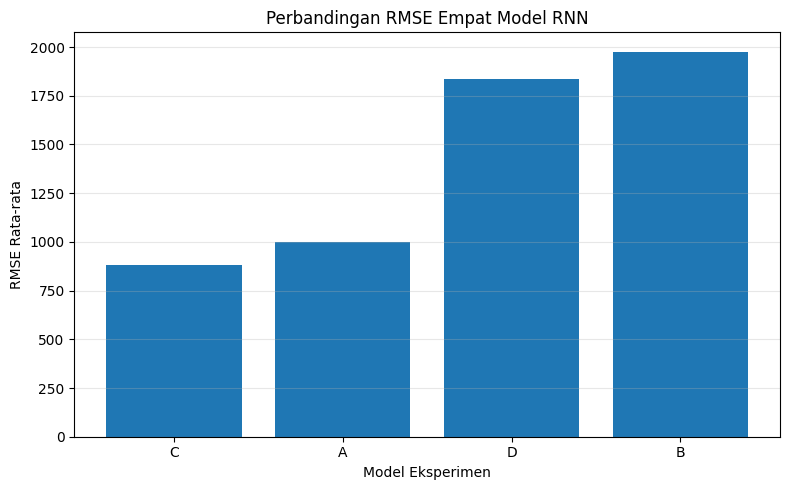

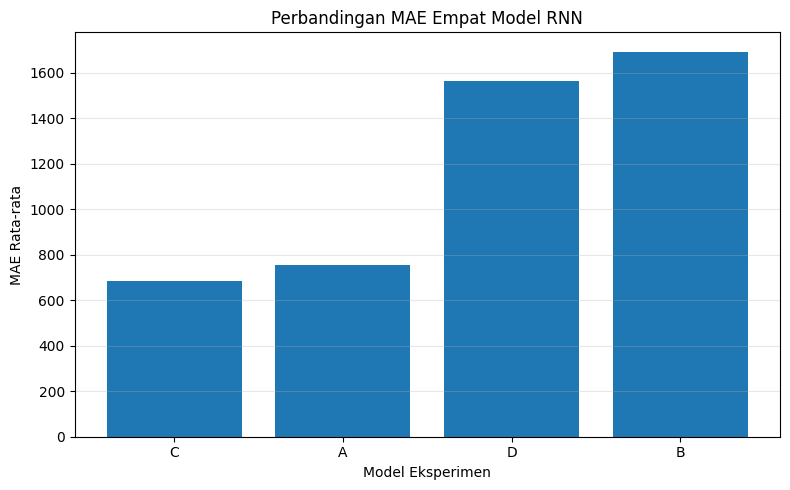

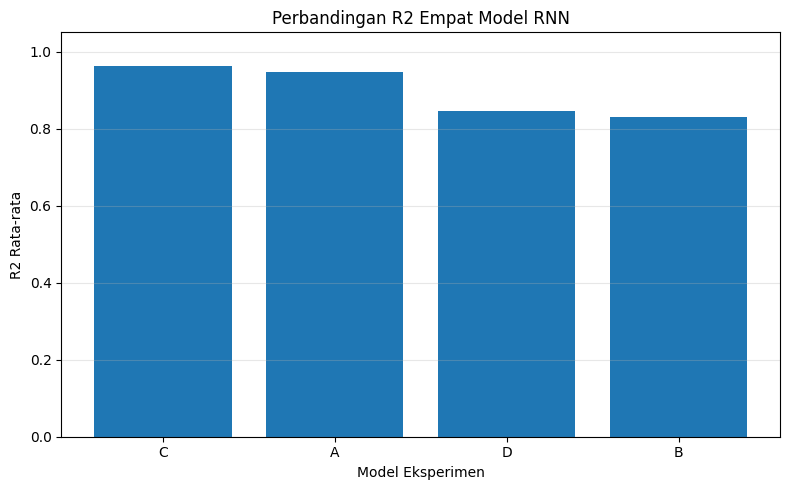

=== DOKUMENTASI MINGGU 14 ===
Grafik RMSE berhasil dibuat.
Grafik MAE berhasil dibuat.
Grafik R2 berhasil dibuat.
Tabel perbandingan berhasil disimpan.

Visualisasi Tahap 20A berhasil.


In [24]:

import matplotlib.pyplot as plt
import pandas as pd

# Data berasal dari hasil evaluasi Tahap 19E
data_grafik = df_ringkasan_ABCD.copy()

# Menentukan label model
data_grafik["Label"] = (
    data_grafik["Model"].str.split(":").str[0]
)

# 1. Grafik perbandingan RMSE
plt.figure(figsize=(8, 5))

plt.bar(
    data_grafik["Label"],
    data_grafik["RMSE"]
)

plt.title("Perbandingan RMSE Empat Model RNN")
plt.xlabel("Model Eksperimen")
plt.ylabel("RMSE Rata-rata")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "W14_Perbandingan_RMSE.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Grafik perbandingan MAE
plt.figure(figsize=(8, 5))

plt.bar(
    data_grafik["Label"],
    data_grafik["MAE"]
)

plt.title("Perbandingan MAE Empat Model RNN")
plt.xlabel("Model Eksperimen")
plt.ylabel("MAE Rata-rata")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "W14_Perbandingan_MAE.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 3. Grafik perbandingan R2
plt.figure(figsize=(8, 5))

plt.bar(
    data_grafik["Label"],
    data_grafik["R2"]
)

plt.title("Perbandingan R2 Empat Model RNN")
plt.xlabel("Model Eksperimen")
plt.ylabel("R2 Rata-rata")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "W14_Perbandingan_R2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Menyimpan tabel hasil
df_ringkasan_ABCD.to_csv(
    "W14_Perbandingan_4_Model.csv",
    index=False
)

print("=== DOKUMENTASI MINGGU 14 ===")
print("Grafik RMSE berhasil dibuat.")
print("Grafik MAE berhasil dibuat.")
print("Grafik R2 berhasil dibuat.")
print("Tabel perbandingan berhasil disimpan.")
print("\nVisualisasi Tahap 20A berhasil.")

**Interpretasi Hasil Tahap 20A**

Visualisasi perbandingan empat model menunjukkan bahwa Model C (PSO + RNN) memiliki performa terbaik berdasarkan tiga metrik evaluasi. Model tersebut memperoleh rata-rata RMSE sebesar 879,7508 dan MAE sebesar 685,0237, serta nilai R² sebesar 0,9636. Model A (*Baseline RNN*) menempati urutan kedua, sedangkan Model D (GA + PSO + RNN) dan Model B (GA + RNN) menunjukkan tingkat kesalahan yang lebih tinggi. Temuan ini memperlihatkan bahwa optimasi hiperparameter menggunakan PSO memberikan hasil yang lebih baik pada konfigurasi eksperimen yang diuji. Sebaliknya, penggunaan fitur hasil seleksi GA belum meningkatkan akurasi prediksi. Hasil tersebut perlu dipahami dengan mempertimbangkan keterbatasan proses optimasi, terutama penggunaan sampel terbatas dalam pencarian hiperparameter.

### 20B. Penyimpanan Model dan Hasil Eksperimen

**Tujuan**

Tahap ini bertujuan untuk menyimpan bobot terbaik keempat model RNN, parameter normalisasi, konfigurasi eksperimen, serta hasil evaluasi agar dapat digunakan kembali pada proses integrasi dashboard Streamlit.

**Hasil yang Diharapkan**

Diperoleh berkas model dan hasil eksperimen dalam folder keluaran Minggu 14, sehingga pelatihan model tidak perlu diulang hanya untuk menampilkan hasil prediksi pada tahap pengembangan berikutnya.

In [25]:

from pathlib import Path
import torch
import joblib
import json
import shutil

# Folder penyimpanan hasil Minggu 14
folder_hasil = Path("/content/W14_Hasil")
folder_hasil.mkdir(exist_ok=True)

# 1. Menyimpan bobot terbaik setiap model
model_data = {
    "A": (best_state_A, 18, 64, 144, 0.001),
    "B": (best_state_B, 10, 64, 144, 0.001),
    "C": (
        best_state_C,
        18,
        cfg_C["hidden_units"],
        cfg_C["sequence_length"],
        cfg_C["learning_rate"]
    ),
    "D": (
        best_state_D,
        10,
        cfg_D["hidden_units"],
        cfg_D["sequence_length"],
        cfg_D["learning_rate"]
    )
}

for nama, (bobot, fitur, hidden, seq, lr) in model_data.items():
    torch.save({
        "state_dict": bobot,
        "input_size": fitur,
        "hidden_units": int(hidden),
        "sequence_length": int(seq),
        "learning_rate": float(lr)
    }, folder_hasil / f"Model_{nama}.pth")

# 2. Menyimpan scaler
joblib.dump(scaler_X, folder_hasil / "scaler_X.pkl")
joblib.dump(scaler_y, folder_hasil / "scaler_y.pkl")

# 3. Menyimpan konfigurasi fitur
konfigurasi_w14 = {
    "fitur_kandidat": fitur_kandidat,
    "fitur_ga": fitur_ga,
    "target_cols": target_cols,
    "jumlah_testing": 7842,
    "urutan_model": ["C", "A", "D", "B"]
}

with open(
    folder_hasil / "konfigurasi_W14.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(konfigurasi_w14, f, indent=4)

# 4. Menyimpan tabel evaluasi
df_ringkasan_ABCD.to_csv(
    folder_hasil / "Perbandingan_4_Model.csv",
    index=False
)

df_perbandingan_ABCD.to_csv(
    folder_hasil / "Evaluasi_Per_Zona.csv",
    index=False
)

# 5. Menyimpan riwayat optimasi PSO
df_log_pso_C_awal.to_csv(
    folder_hasil / "PSO_Log_Model_C.csv",
    index=False
)

df_log_pso_D_awal.to_csv(
    folder_hasil / "PSO_Log_Model_D.csv",
    index=False
)

# 6. Menyalin grafik yang sudah dibuat
for nama_file in [
    "W14_Perbandingan_RMSE.png",
    "W14_Perbandingan_MAE.png",
    "W14_Perbandingan_R2.png"
]:
    sumber = Path("/content") / nama_file
    if sumber.exists():
        shutil.copy2(
            sumber,
            folder_hasil / nama_file
        )

print("=== PENYIMPANAN HASIL MINGGU 14 ===")
for file in sorted(folder_hasil.iterdir()):
    print("Berhasil:", file.name)

print("\nJumlah file:", len(list(folder_hasil.iterdir())))
print("Lokasi:", folder_hasil)
print("\nPenyimpanan sementara berhasil.")

=== PENYIMPANAN HASIL MINGGU 14 ===
Berhasil: Evaluasi_Per_Zona.csv
Berhasil: Model_A.pth
Berhasil: Model_B.pth
Berhasil: Model_C.pth
Berhasil: Model_D.pth
Berhasil: PSO_Log_Model_C.csv
Berhasil: PSO_Log_Model_D.csv
Berhasil: Perbandingan_4_Model.csv
Berhasil: W14_Perbandingan_MAE.png
Berhasil: W14_Perbandingan_R2.png
Berhasil: W14_Perbandingan_RMSE.png
Berhasil: konfigurasi_W14.json
Berhasil: scaler_X.pkl
Berhasil: scaler_y.pkl

Jumlah file: 14
Lokasi: /content/W14_Hasil

Penyimpanan sementara berhasil.


### 20C. Penyimpanan Permanen Hasil Eksperimen

Tahap ini bertujuan untuk menyimpan seluruh hasil eksperimen Minggu 14 ke Google Drive. Berkas yang disimpan meliputi bobot terbaik keempat model RNN, parameter normalisasi, konfigurasi fitur, hasil evaluasi, grafik perbandingan, dan log optimasi PSO. Penyimpanan dilakukan agar hasil penelitian tetap tersedia meskipun sesi Google Colab berakhir dan dapat digunakan kembali untuk pengembangan dashboard Streamlit pada tahap berikutnya.

In [26]:

from google.colab import drive
from pathlib import Path
import shutil

# Menghubungkan Google Colab dengan Google Drive
drive.mount('/content/drive')

# Lokasi sumber dan tujuan
sumber = Path('/content/W14_Hasil')
tujuan = Path('/content/drive/MyDrive/W14_Hasil')

# Memastikan folder sumber tersedia
assert sumber.exists(), "Folder W14_Hasil tidak ditemukan"

# Menyalin seluruh hasil ke Google Drive
shutil.copytree(
    sumber,
    tujuan,
    dirs_exist_ok=True
)

# Memeriksa hasil penyimpanan
file_sumber = sorted(
    f.name for f in sumber.iterdir() if f.is_file()
)

file_tujuan = sorted(
    f.name for f in tujuan.iterdir() if f.is_file()
)

assert file_sumber == file_tujuan

print("=== PENYIMPANAN GOOGLE DRIVE ===")
print("Jumlah file:", len(file_tujuan))
print("Lokasi:", tujuan)

for nama in file_tujuan:
    print("Berhasil:", nama)

print("\nSeluruh hasil berhasil disalin ke Google Drive.")

Mounted at /content/drive
=== PENYIMPANAN GOOGLE DRIVE ===
Jumlah file: 14
Lokasi: /content/drive/MyDrive/W14_Hasil
Berhasil: Evaluasi_Per_Zona.csv
Berhasil: Model_A.pth
Berhasil: Model_B.pth
Berhasil: Model_C.pth
Berhasil: Model_D.pth
Berhasil: PSO_Log_Model_C.csv
Berhasil: PSO_Log_Model_D.csv
Berhasil: Perbandingan_4_Model.csv
Berhasil: W14_Perbandingan_MAE.png
Berhasil: W14_Perbandingan_R2.png
Berhasil: W14_Perbandingan_RMSE.png
Berhasil: konfigurasi_W14.json
Berhasil: scaler_X.pkl
Berhasil: scaler_y.pkl

Seluruh hasil berhasil disalin ke Google Drive.


### 20D. Visualisasi Aktual dan Prediksi Model Terbaik

**Tujuan**

Tahap ini bertujuan untuk memvisualisasikan kesesuaian antara nilai konsumsi listrik aktual dan hasil prediksi Model C (PSO + RNN) pada tiga zona Kota Tetouan.

**Proses yang Dilakukan**

Visualisasi menggunakan 144 observasi pertama pada data pengujian, yang mewakili pengamatan selama 24 jam dengan interval 10 menit. Setiap zona ditampilkan dalam grafik garis yang membandingkan nilai aktual dan prediksi. Model C dipilih karena memperoleh rata-rata RMSE terendah pada eksperimen Minggu 14.

**Hasil yang Diharapkan**

Diperoleh tiga grafik aktual versus prediksi untuk Zona 1, Zona 2, dan Zona 3. Grafik digunakan untuk mengamati kemampuan model dalam mengikuti perubahan konsumsi listrik serta mengidentifikasi periode ketika terdapat perbedaan antara prediksi dan nilai aktual.

=== GRAFIK AKTUAL VS PREDIKSI MODEL C ===


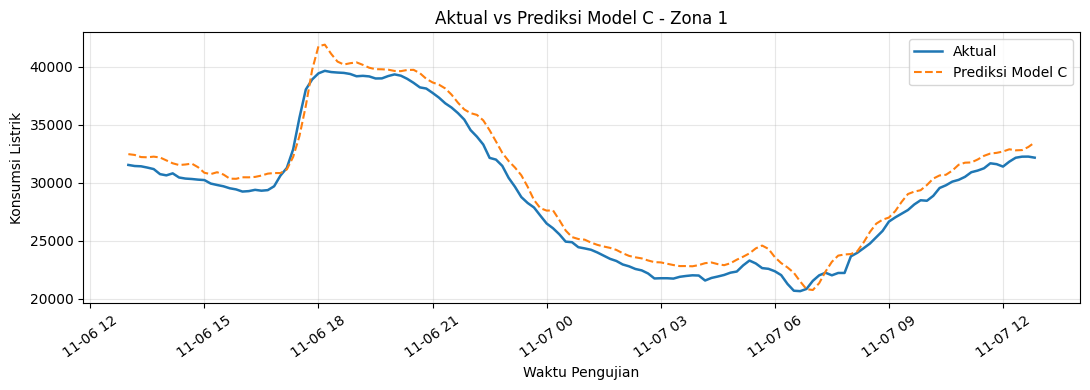

Grafik Zona 1 berhasil disimpan.


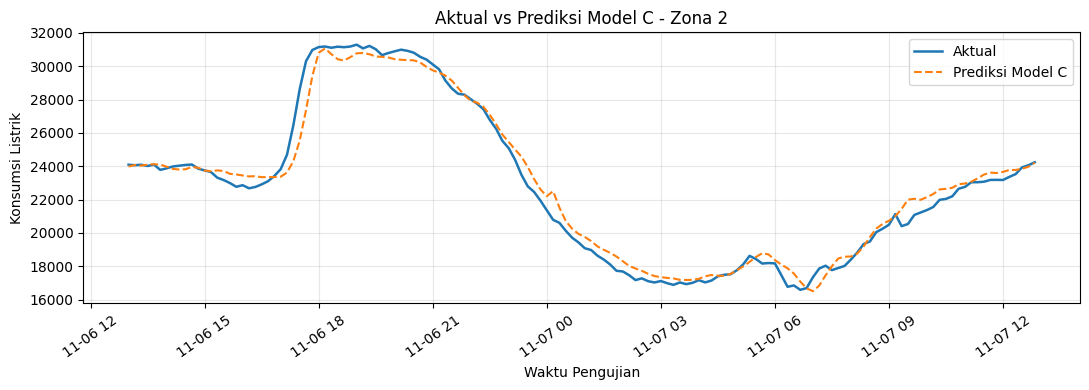

Grafik Zona 2 berhasil disimpan.


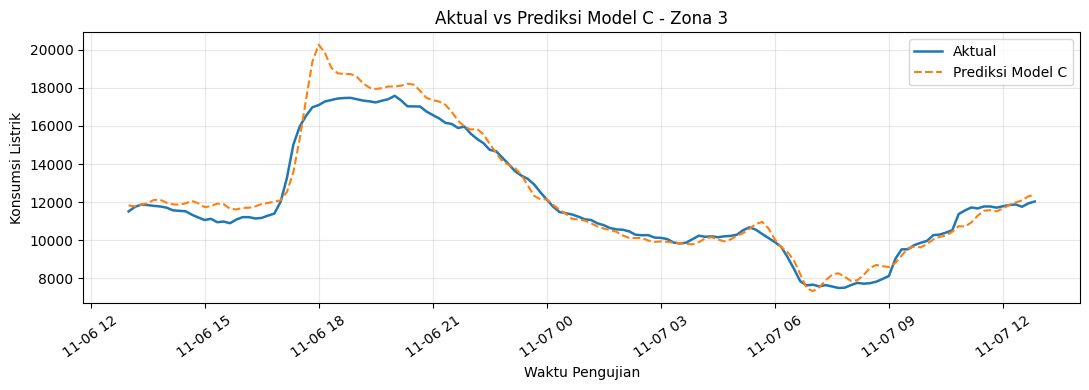

Grafik Zona 3 berhasil disimpan.

Visualisasi aktual versus prediksi berhasil.


In [27]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Menggunakan hasil prediksi Model C dari Tahap 15
jumlah_tampil = 144

# Memastikan hasil prediksi masih tersedia
assert aktual_C_asli.shape == prediksi_C_asli.shape
assert len(aktual_C_asli) == len(df_test)

# Mengambil waktu pengujian
waktu_grafik = df_test["DateTime"].iloc[:jumlah_tampil]

# Folder penyimpanan grafik
folder_hasil = Path("/content/W14_Hasil")
folder_hasil.mkdir(exist_ok=True)

print("=== GRAFIK AKTUAL VS PREDIKSI MODEL C ===")

for i in range(3):

    aktual = aktual_C_asli[:jumlah_tampil, i]
    prediksi = prediksi_C_asli[:jumlah_tampil, i]

    plt.figure(figsize=(11, 4))

    plt.plot(
        waktu_grafik,
        aktual,
        label="Aktual",
        linewidth=1.8
    )

    plt.plot(
        waktu_grafik,
        prediksi,
        label="Prediksi Model C",
        linewidth=1.5,
        linestyle="--"
    )

    plt.title(
        f"Aktual vs Prediksi Model C - Zona {i+1}"
    )
    plt.xlabel("Waktu Pengujian")
    plt.ylabel("Konsumsi Listrik")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=35)
    plt.tight_layout()

    nama_file = (
        f"W14_Aktual_Prediksi_Zona_{i+1}.png"
    )

    plt.savefig(
        folder_hasil / nama_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Grafik Zona {i+1} berhasil disimpan.")

print("\nVisualisasi aktual versus prediksi berhasil.")

**Interpretasi Hasil Tahap 20D**

Visualisasi aktual dan prediksi Model C memperlihatkan bahwa RNN yang dioptimalkan menggunakan PSO mampu mengikuti pola perubahan konsumsi listrik pada ketiga zona selama 24 jam pertama periode pengujian. Pada Zona 1, nilai prediksi cenderung sedikit lebih tinggi dibandingkan nilai aktual pada beberapa interval. Zona 2 menunjukkan kedekatan antara kedua garis, meskipun masih terlihat perbedaan ketika konsumsi berubah secara cepat. Sementara itu, Zona 3 memperlihatkan penyimpangan yang lebih jelas saat terjadi kenaikan konsumsi menuju puncak. Kondisi tersebut menunjukkan bahwa model telah mempelajari pola temporal secara umum, tetapi belum sepenuhnya mampu memperkirakan besarnya perubahan konsumsi pada setiap interval. Temuan visual ini melengkapi hasil evaluasi numerik Model C yang memperoleh rata-rata RMSE sebesar 879,7508 dan R² sebesar 0,9636 pada keseluruhan data pengujian.

### 20E. Visualisasi Kesalahan Prediksi terhadap Waktu

**Tujuan**

Tahap ini bertujuan untuk menganalisis kesalahan prediksi Model C pada setiap zona berdasarkan selisih antara konsumsi listrik aktual dan hasil prediksi.

**Proses yang Dilakukan**

Kesalahan prediksi dihitung dengan mengurangkan nilai prediksi dari nilai aktual pada 144 observasi pertama periode pengujian. Hasilnya divisualisasikan terhadap waktu untuk mengidentifikasi perubahan arah dan besarnya kesalahan. Garis horizontal bernilai nol digunakan sebagai acuan prediksi tanpa kesalahan.

**Hasil yang Diharapkan**

Diperoleh tiga grafik kesalahan prediksi yang menunjukkan periode ketika model menghasilkan prediksi lebih tinggi atau lebih rendah daripada konsumsi aktual. Grafik digunakan sebagai pelengkap evaluasi MAE, RMSE, dan R².

=== GRAFIK ERROR MODEL C ===


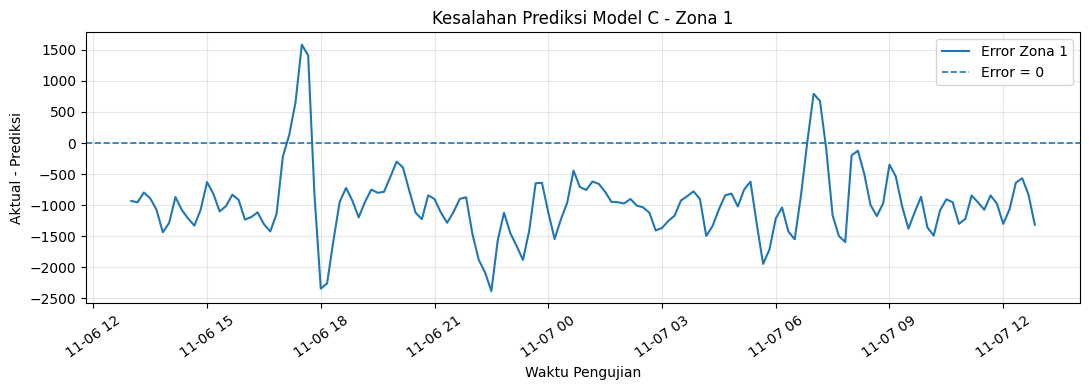

Zona 1 | Rata-rata error: -971.46 | MAE 24 jam: 1044.57


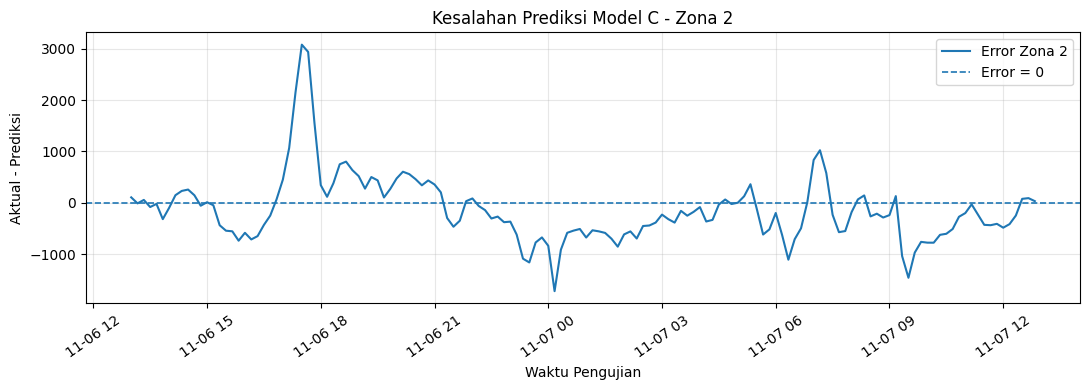

Zona 2 | Rata-rata error: -139.83 | MAE 24 jam: 480.18


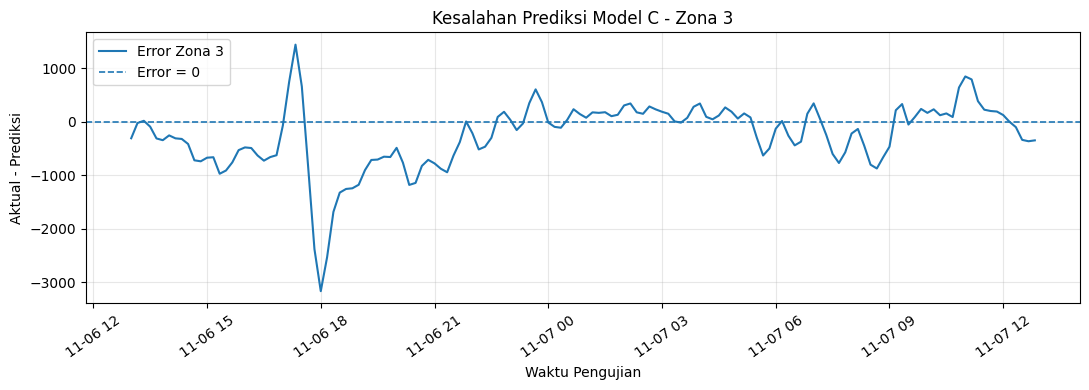

Zona 3 | Rata-rata error: -257.61 | MAE 24 jam: 461.77

Tiga grafik error berhasil dibuat.


In [28]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# TAHAP 20E: ERROR TERHADAP WAKTU MODEL C
# ==========================================

jumlah_tampil = 144

# Menggunakan hasil evaluasi Model C
aktual = aktual_C_asli[:jumlah_tampil]
prediksi = prediksi_C_asli[:jumlah_tampil]

# Error positif: prediksi terlalu rendah
# Error negatif: prediksi terlalu tinggi
error_C = aktual - prediksi

waktu = df_test["DateTime"].iloc[:jumlah_tampil]

folder_hasil = Path("/content/W14_Hasil")
folder_hasil.mkdir(exist_ok=True)

print("=== GRAFIK ERROR MODEL C ===")

for i in range(3):

    error_zona = error_C[:, i]

    plt.figure(figsize=(11, 4))

    plt.plot(
        waktu,
        error_zona,
        label=f"Error Zona {i+1}",
        linewidth=1.5
    )

    plt.axhline(
        y=0,
        linestyle="--",
        linewidth=1.2,
        label="Error = 0"
    )

    plt.title(
        f"Kesalahan Prediksi Model C - Zona {i+1}"
    )

    plt.xlabel("Waktu Pengujian")
    plt.ylabel("Aktual - Prediksi")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=35)
    plt.tight_layout()

    nama_file = (
        f"W14_Error_Zona_{i+1}.png"
    )

    plt.savefig(
        folder_hasil / nama_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"Zona {i+1} | "
        f"Rata-rata error: {error_zona.mean():.2f} | "
        f"MAE 24 jam: {np.abs(error_zona).mean():.2f}"
    )

print("\nTiga grafik error berhasil dibuat.")

**Interpretasi Hasil Tahap 20E**

Visualisasi kesalahan prediksi Model C menunjukkan adanya perbedaan karakteristik kesalahan pada ketiga zona selama 24 jam pertama periode pengujian. Zona 1 menghasilkan rata-rata kesalahan sebesar -971,46 dengan MAE 1.044,57, yang menunjukkan kecenderungan prediksi lebih tinggi dibandingkan konsumsi aktual. Pada Zona 2, rata-rata kesalahan sebesar -139,83 dengan MAE 480,18 memperlihatkan penyimpangan yang relatif lebih kecil, meskipun terdapat lonjakan kesalahan ketika konsumsi listrik mengalami perubahan cepat. Sementara itu, Zona 3 menghasilkan rata-rata kesalahan sebesar -257,61 dan MAE 461,77, dengan penyimpangan yang cukup besar pada periode kenaikan konsumsi menuju puncak. Secara keseluruhan, kesalahan prediksi tidak tersebar secara seragam sepanjang waktu. Temuan ini menunjukkan bahwa Model C mampu mengikuti pola konsumsi secara umum, tetapi masih memiliki keterbatasan dalam memperkirakan perubahan beban yang berlangsung mendadak.

## Kesimpulan Progres Minggu 14

Implementasi *Particle Swarm Optimization* (PSO) pada Model C dan Model D berhasil dilakukan untuk mengoptimalkan jumlah *hidden units*, panjang *sequence*, dan *learning rate* RNN. Proses optimasi menggunakan enam partikel dan lima iterasi, kemudian konfigurasi terpilih digunakan dalam pelatihan serta pengujian konsumsi listrik pada tiga zona Kota Tetouan. Hasil pencarian PSO awal diperoleh melalui pelatihan singkat menggunakan sampel terbatas, sedangkan evaluasi akhir dilakukan setelah pelatihan menggunakan keseluruhan sampel yang telah disiapkan.

Berdasarkan pengujian terhadap 7.842 sampel yang sama, Model C (PSO + RNN) memperoleh performa terbaik di antara empat konfigurasi eksperimen dengan rata-rata MAE sebesar 685,0237, RMSE sebesar 879,7508, dan R² sebesar 0,9636. Model A (*Baseline RNN*) menempati posisi kedua, diikuti Model D (GA + PSO + RNN) dan Model B (GA + RNN). Hasil ini menunjukkan bahwa penerapan PSO memberikan peningkatan performa dibandingkan konfigurasi dasar pada eksperimen yang dilakukan. Sebaliknya, penggunaan 10 fitur hasil seleksi GA belum menghasilkan akurasi yang lebih baik dibandingkan model dengan 18 fitur masukan.

Visualisasi aktual dan prediksi menunjukkan bahwa Model C mampu mengikuti pola konsumsi listrik pada ketiga zona, meskipun masih terdapat penyimpangan ketika beban mengalami perubahan cepat. Hasil penelitian ini juga memiliki keterbatasan karena seleksi fitur GA mengacu pada eksperimen Minggu 13 dengan protokol berbeda, sedangkan pencarian PSO dilakukan menggunakan sampel terbatas dan satu *epoch*. Oleh karena itu, peringkat model yang diperoleh merupakan hasil empiris pada pengaturan eksperimen ini dan belum dapat digeneralisasi sebagai keunggulan mutlak suatu algoritma. Model C selanjutnya dapat digunakan sebagai kandidat utama untuk integrasi prediksi dan pengembangan sistem *Fuzzy Logic* pada Minggu 15.

In [29]:

from pathlib import Path
import shutil

sumber = Path("/content/W14_Hasil")
tujuan = Path("/content/drive/MyDrive/W14_Hasil")

tujuan.mkdir(parents=True, exist_ok=True)

grafik_baru = [
    f"W14_Aktual_Prediksi_Zona_{i}.png"
    for i in range(1, 4)
] + [
    f"W14_Error_Zona_{i}.png"
    for i in range(1, 4)
]

for nama in grafik_baru:
    assert (sumber / nama).exists(), f"File tidak ada: {nama}"
    shutil.copy2(sumber / nama, tujuan / nama)
    print("Berhasil disimpan:", nama)

assert all((tujuan / nama).exists() for nama in grafik_baru)

print("\nEnam grafik baru berhasil disimpan.")
print("Total file di My Drive:", len(list(tujuan.iterdir())))

Berhasil disimpan: W14_Aktual_Prediksi_Zona_1.png
Berhasil disimpan: W14_Aktual_Prediksi_Zona_2.png
Berhasil disimpan: W14_Aktual_Prediksi_Zona_3.png
Berhasil disimpan: W14_Error_Zona_1.png
Berhasil disimpan: W14_Error_Zona_2.png
Berhasil disimpan: W14_Error_Zona_3.png

Enam grafik baru berhasil disimpan.
Total file di My Drive: 20
